In [1]:
# ============================================================
# CELL 1 — MENTALBERT + AGGRESSIVE CLEANING SETUP
# ============================================================

import os
import re
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("=" * 60)
print("MENTALBERT + AGGRESSIVE CLEANING")
print("=" * 60)

print()
print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )

# ------------------------------------------------------------
# EXPERIMENT IDENTITY
# ------------------------------------------------------------

EXPERIMENT_NAME = (
    "AGGRESSIVE + MentalBERT"
)

CLEANING_METHOD = (
    "Aggressive cleaning after diagnostic anchor removal"
)

MODEL_NAME = (
    "mental/mental-bert-base-uncased"
)

MAX_LENGTH = 512

print()
print("Model:", MODEL_NAME)
print("Cleaning:", CLEANING_METHOD)
print("Context length:", MAX_LENGTH)

# ------------------------------------------------------------
# CLEANING POLICY
# ------------------------------------------------------------

print()
print("=" * 60)
print("AGGRESSIVE CLEANING POLICY")
print("=" * 60)

aggressive_cleaning_steps = [

    "Remove RT markers",

    "Remove URLs",

    "Remove mentions",

    "Remove hashtags",

    "Remove HTML entities",

    "Remove emojis / non-ASCII symbols",

    "Remove punctuation",

    "Remove digits",

    "Normalize repeated-character noise",

    "Lowercase",

    "Normalize whitespace"
]

for i, step in enumerate(
    aggressive_cleaning_steps,
    start=1
):

    print(
        f"{i:02d}. {step}"
    )

# ------------------------------------------------------------
# RESULT DIRECTORIES
# ------------------------------------------------------------

MENTAL_AGG_RESULT_DIR = (
    "/kaggle/working/"
    "mentalbert_aggressive_results"
)

MENTAL_AGG_CHECKPOINT_DIR = (
    "/kaggle/working/"
    "mentalbert_aggressive_checkpoints"
)

MENTAL_AGG_BACKUP_DIR = (
    "/kaggle/working/"
    "MentalBERT_Aggressive_FINAL_BACKUP"
)

os.makedirs(
    MENTAL_AGG_RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    MENTAL_AGG_CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    MENTAL_AGG_BACKUP_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

MENTAL_AGG_CONFIG = {

    "experiment":
        EXPERIMENT_NAME,

    "model":
        "MentalBERT",

    "checkpoint":
        MODEL_NAME,

    "cleaning":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "seed":
        SEED,

    "device":
        str(device),

    "metadata_features":
        53,

    "additional_cleaning":
        True,

    "cleaning_steps":
        aggressive_cleaning_steps,

    "fixed_controls": [

        "Exact user-level split",

        "Diagnostic anchor detection",

        "Diagnostic anchor removal",

        "D2 preservation",

        "53 metadata features",

        "Train-only StandardScaler",

        "Train-only random undersampling",

        "512-token model input",

        "Held-out test evaluation"
    ]
}

with open(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_experiment_config.json"
    ),
    "w"
) as f:

    json.dump(
        MENTAL_AGG_CONFIG,
        f,
        indent=2
    )

# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print("✓ MentalBERT selected")
print("✓ Aggressive cleaning selected")
print("✓ Context length = 512")
print("✓ Seed = 42")
print("✓ Cleaning policy defined")
print("✓ Result directory created")
print("✓ Checkpoint directory created")
print("✓ Backup directory created")
print("✓ RAW / Selective / Emotion outputs untouched")

MENTALBERT + AGGRESSIVE CLEANING

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: mental/mental-bert-base-uncased
Cleaning: Aggressive cleaning after diagnostic anchor removal
Context length: 512

AGGRESSIVE CLEANING POLICY
01. Remove RT markers
02. Remove URLs
03. Remove mentions
04. Remove hashtags
05. Remove HTML entities
06. Remove emojis / non-ASCII symbols
07. Remove punctuation
08. Remove digits
09. Normalize repeated-character noise
10. Lowercase
11. Normalize whitespace

CELL 1 COMPLETE
✓ MentalBERT selected
✓ Aggressive cleaning selected
✓ Context length = 512
✓ Seed = 42
✓ Cleaning policy defined
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ RAW / Selective / Emotion outputs untouched


In [2]:
# ============================================================
# CELL 2 — MENTALBERT + AGGRESSIVE
# LOAD EXACT USER-LEVEL SPLIT
# SAME SPLIT AS RAW / E2 / E3 / E4
# ============================================================

print("=" * 60)
print("MENTALBERT AGGRESSIVE — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)


# ------------------------------------------------------------
# SPLIT ROOT
# ------------------------------------------------------------

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)

print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)


# ------------------------------------------------------------
# FILE CHECK
# ------------------------------------------------------------

for path in [
    TRAIN_PATH,
    VAL_PATH,
    TEST_PATH
]:

    assert os.path.exists(
        path
    ), (
        f"Missing split file:\n{path}"
    )

print()
print("✓ All split files found")


# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

print()
print("Loading TRAIN...")

train_df = pd.read_pickle(
    TRAIN_PATH
)

print("Loading VALIDATION...")

val_df = pd.read_pickle(
    VAL_PATH
)

print("Loading TEST...")

test_df = pd.read_pickle(
    TEST_PATH
)


# ------------------------------------------------------------
# SHAPES
# ------------------------------------------------------------

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

assert len(train_df) == 6135
assert len(val_df) == 767
assert len(test_df) == 767


# ------------------------------------------------------------
# REQUIRED COLUMNS
# ------------------------------------------------------------

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns

    print(
        f"✓ {column}"
    )


# ------------------------------------------------------------
# USER-LEVEL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)

print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)

assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique


print(
    "TRAIN ↔ VAL:",
    len(
        train_users & val_users
    )
)

print(
    "TRAIN ↔ TEST:",
    len(
        train_users & test_users
    )
)

print(
    "VAL ↔ TEST:",
    len(
        val_users & test_users
    )
)

assert len(
    train_users & val_users
) == 0

assert len(
    train_users & test_users
) == 0

assert len(
    val_users & test_users
) == 0

print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")


# ------------------------------------------------------------
# LABEL DISTRIBUTION
# ------------------------------------------------------------

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# EXACT LABEL CHECK
# ------------------------------------------------------------

assert (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 4122,
        1: 2013
    }
)

assert (
    val_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 515,
        1: 252
    }
)

assert (
    test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 516,
        1: 251
    }
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact user-level split restored")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same user IDs as previous experiments")
print("✓ Same labels")
print("✓ No cross-split overlap")
print("✓ Timeline text available")

MENTALBERT AGGRESSIVE — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

CELL 2 COMPLETE
✓ Exact user-level split restored
✓ TRAIN = 613

In [3]:
# ============================================================
# CELL 3 — MENTALBERT + AGGRESSIVE
# EXACT D1 ANCHOR DETECTION
# SAME CONTROL AS RAW / E2 / E3 / E4
# ============================================================

import os
import re
import json
import glob
from collections import defaultdict

print("=" * 60)
print("MENTALBERT AGGRESSIVE — EXACT D1 ANCHOR DETECTION")
print("=" * 60)


# ------------------------------------------------------------
# ORIGINAL DATASET
# ------------------------------------------------------------

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

positive_timeline_dir = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    positive_timeline_dir
)

positive_timeline_files = glob.glob(
    os.path.join(
        positive_timeline_dir,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(positive_timeline_files)
)

assert len(
    positive_timeline_files
) == 2626


# ------------------------------------------------------------
# EXACT REFINED ANCHOR PATTERNS
# ------------------------------------------------------------

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    r"\b(?:my|a)\s+(?:doctor|psychiatrist)\s+(?:has\s+)?diagnosed\s+me\b.{0,80}\bdepress"
]

REFINED_COMPILED_PATTERNS = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in REFINED_ANCHOR_PATTERNS
]


# ------------------------------------------------------------
# EXCLUSION PATTERNS
# ------------------------------------------------------------

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]

COMPILED_EXCLUSION_PATTERNS = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in EXCLUSION_PATTERNS
]


# ------------------------------------------------------------
# DETECTOR
# ------------------------------------------------------------

def is_refined_anchor_tweet(text):

    if text is None:
        return False

    text = str(text).strip()

    if not text:
        return False

    for pattern in COMPILED_EXCLUSION_PATTERNS:

        if pattern.search(text):
            return False

    for pattern in REFINED_COMPILED_PATTERNS:

        if pattern.search(text):
            return True

    return False


# ------------------------------------------------------------
# POSITIVE USERS BY SPLIT
# ------------------------------------------------------------

train_positive_usernames = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ].astype(str)
)

val_positive_usernames = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ].astype(str)
)

test_positive_usernames = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ].astype(str)
)

all_positive_split_usernames = (
    train_positive_usernames
    | val_positive_usernames
    | test_positive_usernames
)

print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_usernames)
)

print(
    "VALIDATION:",
    len(val_positive_usernames)
)

print(
    "TEST:",
    len(test_positive_usernames)
)

assert len(
    train_positive_usernames
) == 2013

assert len(
    val_positive_usernames
) == 252

assert len(
    test_positive_usernames
) == 251

assert len(
    all_positive_split_usernames
) == 2516


# ------------------------------------------------------------
# INDEX TIMELINE FILES
# ------------------------------------------------------------

positive_files_by_user = defaultdict(list)

for timeline_file in positive_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    positive_files_by_user[
        username
    ].append(
        timeline_file
    )

assert len(
    positive_files_by_user
) == 2516


# ------------------------------------------------------------
# EXACT SCAN
# ------------------------------------------------------------

split_anchor_records = []

users_processed = set()
tweets_scanned = 0

for username in sorted(
    all_positive_split_usernames
):

    if username not in positive_files_by_user:

        raise KeyError(
            f"Missing timeline for user: {username}"
        )

    users_processed.add(
        username
    )

    for timeline_file in (
        positive_files_by_user[username]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = record.get(
                    "id_str",
                    record.get(
                        "id",
                        ""
                    )
                )

                tweet_text = record.get(
                    "text",
                    ""
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    split_anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                str(tweet_id),

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                str(tweet_text)
                        }
                    )


# ------------------------------------------------------------
# UNIQUE ANCHOR PAIRS
# ------------------------------------------------------------

exact_anchor_pairs = {
    (
        record["username"],
        record["tweet_id"]
    )
    for record in split_anchor_records
}


# ------------------------------------------------------------
# SPLIT-SPECIFIC ANCHORS
# ------------------------------------------------------------

train_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in train_positive_usernames
}

val_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in val_positive_usernames
}

test_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in test_positive_usernames
}


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(split_anchor_records)
)

print(
    "Unique anchor pairs:",
    len(exact_anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ------------------------------------------------------------
# EXACT CONTROL ASSERTIONS
# ------------------------------------------------------------

assert len(
    users_processed
) == 2516

assert len(
    split_anchor_records
) == 1920

assert len(
    exact_anchor_pairs
) == 1847

assert len(
    train_anchor_pairs
) == 1476

assert len(
    val_anchor_pairs
) == 190

assert len(
    test_anchor_pairs
) == 181


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

mentalbert_aggressive_anchor_df = pd.DataFrame(
    split_anchor_records
)

mentalbert_aggressive_anchor_df.to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_exact_anchor_records.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print("✓ Exact E3/E4 anchor detector reproduced")
print("✓ 1,847 unique anchors confirmed")
print("✓ 1,920 anchor records confirmed")
print("✓ TRAIN = 1,476 unique anchors")
print("✓ VAL = 190 unique anchors")
print("✓ TEST = 181 unique anchors")
print("✓ No D2 users included")
print("✓ Anchor records saved")
print("✓ No timelines modified yet")

MENTALBERT AGGRESSIVE — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact E3/E4 anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — MENTALBERT + AGGRESSIVE
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("MENTALBERT AGGRESSIVE — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)


# ------------------------------------------------------------
# EXPECTED COUNTS
# ------------------------------------------------------------

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED   = 199
EXPECTED_TEST_REMOVED  = 186
EXPECTED_TOTAL_REMOVED = 1920


# ------------------------------------------------------------
# PRE-REMOVAL VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_occurrences = (
    len(split_anchor_records)
    - len(exact_anchor_pairs)
)

print(
    "Raw anchor records:",
    len(split_anchor_records)
)

print(
    "Unique anchor pairs:",
    len(exact_anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_occurrences
)

assert len(split_anchor_records) == 1920
assert len(exact_anchor_pairs) == 1847
assert duplicate_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")


# ------------------------------------------------------------
# SPLIT-LEVEL RECORD COUNTS
# ------------------------------------------------------------

train_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in train_positive_usernames
]

val_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in val_positive_usernames
]

test_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in test_positive_usernames
]

print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected:",
    EXPECTED_TRAIN_REMOVED
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected:",
    EXPECTED_VAL_REMOVED
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected:",
    EXPECTED_TEST_REMOVED
)

assert len(train_anchor_records) == EXPECTED_TRAIN_REMOVED
assert len(val_anchor_records) == EXPECTED_VAL_REMOVED
assert len(test_anchor_records) == EXPECTED_TEST_REMOVED


# ------------------------------------------------------------
# EXACT ANCHOR SET
# ------------------------------------------------------------

EXACT_ANCHOR_SET = set(
    exact_anchor_pairs
)


# ------------------------------------------------------------
# INDEX ORIGINAL D1 TIMELINE FILES
# ------------------------------------------------------------

positive_files_by_user = defaultdict(list)

for timeline_file in positive_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    positive_files_by_user[
        username
    ].append(
        timeline_file
    )

assert len(
    positive_files_by_user
) == 2516


# ------------------------------------------------------------
# BUILD ANCHOR-REMOVED TEXT
# ------------------------------------------------------------

def build_anchor_removed_text(
    username
):

    kept_texts = []

    original_count = 0
    removed_count = 0

    for timeline_file in (
        positive_files_by_user[username]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                original_count += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if text:

                    # IMPORTANT:
                    # No aggressive cleaning here.
                    # This cell ONLY removes anchors.
                    kept_texts.append(
                        text
                    )

    return (
        " ".join(kept_texts),
        original_count,
        removed_count
    )


# ------------------------------------------------------------
# COPY ORIGINAL SPLITS
# ------------------------------------------------------------

train_mental_aggressive_df = train_df.copy(
    deep=True
)

val_mental_aggressive_df = val_df.copy(
    deep=True
)

test_mental_aggressive_df = test_df.copy(
    deep=True
)


# ------------------------------------------------------------
# PROCESS POSITIVE USERS
# ------------------------------------------------------------

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0

for username in sorted(
    all_positive_split_usernames
):

    raw_text, _, removed_count = (
        build_anchor_removed_text(
            username
        )
    )

    positive_anchor_removed_text[
        username
    ] = raw_text

    if username in train_positive_usernames:

        train_removed += removed_count

    elif username in val_positive_usernames:

        val_removed += removed_count

    elif username in test_positive_usernames:

        test_removed += removed_count


# ------------------------------------------------------------
# FINAL REMOVAL VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

print(
    "TOTAL removed:",
    train_removed
    + val_removed
    + test_removed
)

assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED

assert (
    train_removed
    + val_removed
    + test_removed
    == EXPECTED_TOTAL_REMOVED
)

print()
print("✓ Record-level removal exactly matches previous experiments")


# ------------------------------------------------------------
# UPDATE ONLY POSITIVE USERS
# ------------------------------------------------------------

for df in [
    train_mental_aggressive_df,
    val_mental_aggressive_df,
    test_mental_aggressive_df
]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "timeline_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_text
        )
        .fillna("")
        .values
    )


# ------------------------------------------------------------
# TEMPORARY MODEL TEXT
# IMPORTANT:
# STILL ONLY ANCHOR-REMOVED.
# AGGRESSIVE CLEANING COMES IN CELL 5.
# ------------------------------------------------------------

train_mental_aggressive_df[
    "anchor_removed_text"
] = (
    train_mental_aggressive_df[
        "timeline_text"
    ]
    .fillna("")
    .astype(str)
)

val_mental_aggressive_df[
    "anchor_removed_text"
] = (
    val_mental_aggressive_df[
        "timeline_text"
    ]
    .fillna("")
    .astype(str)
)

test_mental_aggressive_df[
    "anchor_removed_text"
] = (
    test_mental_aggressive_df[
        "timeline_text"
    ]
    .fillna("")
    .astype(str)
)


# ------------------------------------------------------------
# D2 PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original, result, name in [

    (
        train_df,
        train_mental_aggressive_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_aggressive_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_aggressive_df,
        "TEST"
    )

]:

    original_d2 = (
        original.loc[
            original["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    result_d2 = (
        result.loc[
            result["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {name} D2 unchanged"
    )


# ------------------------------------------------------------
# USER + LABEL PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original, result, name in [

    (
        train_df,
        train_mental_aggressive_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_aggressive_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_aggressive_df,
        "TEST"
    )

]:

    assert list(
        original["user_id"]
    ) == list(
        result["user_id"]
    )

    assert list(
        original["username"]
    ) == list(
        result["username"]
    )

    assert list(
        original["label"]
    ) == list(
        result["label"]
    )

    print(
        f"✓ {name}: users and labels unchanged"
    )


# ------------------------------------------------------------
# TEXT INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for name, df in [

    (
        "TRAIN",
        train_mental_aggressive_df
    ),

    (
        "VALIDATION",
        val_mental_aggressive_df
    ),

    (
        "TEST",
        test_mental_aggressive_df
    )

]:

    empty_count = int(
        (
            df[
                "anchor_removed_text"
            ]
            .str.strip()
            == ""
        ).sum()
    )

    print(
        f"{name}: "
        f"empty anchor-removed texts = "
        f"{empty_count}"
    )


# ------------------------------------------------------------
# PREVIEW
# ------------------------------------------------------------

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT PREVIEW")
print("=" * 60)

for _, row in (
    train_mental_aggressive_df.head(3).iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        row["anchor_removed_text"][:1000]
    )


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

train_mental_aggressive_df.to_pickle(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_train_anchor_removed.pkl"
    )
)

val_mental_aggressive_df.to_pickle(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_val_anchor_removed.pkl"
    )
)

test_mental_aggressive_df.to_pickle(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_anchor_removed.pkl"
    )
)


print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ No aggressive cleaning applied yet")
print("✓ Anchor-removed source saved")

MENTALBERT AGGRESSIVE — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920

✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

ANCHOR-REMOVED TEXT PREVIEW

User: RompingFox
Label: 1
@cybershot_1 :(

In [5]:
# ============================================================
# CELL 5 — MENTALBERT + AGGRESSIVE CLEANING
# ============================================================

import re
import html
import os
import numpy as np
import pandas as pd

print("=" * 60)
print("MENTALBERT AGGRESSIVE — TEXT CLEANING")
print("=" * 60)


# ------------------------------------------------------------
# AGGRESSIVE CLEANER
# SAME CLEANING POLICY AS E2
# ------------------------------------------------------------

def aggressive_clean_text(text):

    if text is None:
        return ""

    text = str(text)

    # --------------------------------------------------------
    # HTML / ENCODED CHARACTERS
    # --------------------------------------------------------

    text = html.unescape(
        text
    )

    # --------------------------------------------------------
    # REMOVE RETWEET MARKERS
    # --------------------------------------------------------

    text = re.sub(
        r"\bRT\b[:\s]*",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # REMOVE URLs
    # --------------------------------------------------------

    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Twitter-style leftover URL fragments
    text = re.sub(
        r"\bpic\.twitter\.com/\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # REMOVE USER MENTIONS
    # --------------------------------------------------------

    text = re.sub(
        r"@\w+",
        " ",
        text
    )

    # --------------------------------------------------------
    # REMOVE HASHTAGS
    # --------------------------------------------------------

    text = re.sub(
        r"#\w+",
        " ",
        text
    )

    # --------------------------------------------------------
    # REMOVE EMOJIS / NON-ASCII CHARACTERS
    # --------------------------------------------------------

    text = re.sub(
        r"[^\x00-\x7F]+",
        " ",
        text
    )

    # --------------------------------------------------------
    # REMOVE DIGITS
    # --------------------------------------------------------

    text = re.sub(
        r"\d+",
        " ",
        text
    )

    # --------------------------------------------------------
    # NORMALIZE REPEATED CHARACTERS
    #
    # Example:
    # soooo  -> soo
    # goooo  -> goo
    # --------------------------------------------------------

    text = re.sub(
        r"(.)\1{2,}",
        r"\1\1",
        text
    )

    # --------------------------------------------------------
    # REMOVE PUNCTUATION
    # KEEP ALPHANUMERIC CHARACTERS + SPACES
    # --------------------------------------------------------

    text = re.sub(
        r"[^A-Za-z\s]",
        " ",
        text
    )

    # --------------------------------------------------------
    # LOWERCASE
    # --------------------------------------------------------

    text = text.lower()

    # --------------------------------------------------------
    # WHITESPACE NORMALIZATION
    # --------------------------------------------------------

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ------------------------------------------------------------
# SANITY TESTS
# ------------------------------------------------------------

print()
print("=" * 60)
print("AGGRESSIVE CLEANING TEST")
print("=" * 60)

test_examples = [

    (
        "I CAN'T sleep 😭!!! "
        "https://t.co/example @someone #depression",
        "i can t sleep"
    ),

    (
        "RT @user: I am feeling REALLY bad today!!!",
        "i am feeling really bad today"
    ),

    (
        "Everything is okay... or maybe NOT 😔",
        "everything is okay or maybe not"
    ),

    (
        "I have been feeling hopeless for weeks :(",
        "i have been feeling hopeless for weeks"
    ),

    (
        "I am 23 years old and this happened 3 times!!!",
        "i am years old and this happened times"
    ),

    (
        "Feeling sooo tired... but I'm trying :) "
        "#mentalhealth",
        "feeling soo tired but i m trying"
    )
]

for idx, (raw, expected) in enumerate(
    test_examples,
    start=1
):

    cleaned = aggressive_clean_text(
        raw
    )

    print()
    print(
        f"EXAMPLE {idx}"
    )

    print(
        "RAW:"
    )

    print(
        raw
    )

    print(
        "AGGRESSIVELY CLEANED:"
    )

    print(
        cleaned
    )

    assert cleaned == expected

print()
print(
    "✓ All aggressive cleaning sanity tests passed"
)


# ------------------------------------------------------------
# APPLY TO TRAIN / VALIDATION / TEST
# ------------------------------------------------------------

print()
print("=" * 60)
print("APPLYING AGGRESSIVE CLEANING")
print("=" * 60)


train_mental_aggressive_df[
    "model_text"
] = (
    train_mental_aggressive_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .map(
        aggressive_clean_text
    )
)

val_mental_aggressive_df[
    "model_text"
] = (
    val_mental_aggressive_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .map(
        aggressive_clean_text
    )
)

test_mental_aggressive_df[
    "model_text"
] = (
    test_mental_aggressive_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .map(
        aggressive_clean_text
    )
)


# ------------------------------------------------------------
# EMPTY TEXT COUNTS
# ------------------------------------------------------------

print()

for name, df in [

    (
        "TRAIN",
        train_mental_aggressive_df
    ),

    (
        "VALIDATION",
        val_mental_aggressive_df
    ),

    (
        "TEST",
        test_mental_aggressive_df
    )

]:

    empty_count = int(
        (
            df[
                "model_text"
            ]
            .str.strip()
            == ""
        ).sum()
    )

    print(
        f"{name}: "
        f"empty after cleaning: "
        f"{empty_count}"
    )


# ------------------------------------------------------------
# USER / LABEL PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original, result, name in [

    (
        train_df,
        train_mental_aggressive_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_aggressive_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_aggressive_df,
        "TEST"
    )

]:

    assert list(
        original["user_id"]
    ) == list(
        result["user_id"]
    )

    assert list(
        original["label"]
    ) == list(
        result["label"]
    )

    assert list(
        original["username"]
    ) == list(
        result["username"]
    )

    print(
        f"✓ {name}: "
        "users, usernames and labels unchanged"
    )


# ------------------------------------------------------------
# CLEANING VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("AGGRESSIVE CLEANING VERIFICATION")
print("=" * 60)

verification_samples = (
    train_mental_aggressive_df[
        "model_text"
    ]
    .head(100)
    .tolist()
)

for text in verification_samples:

    # URLs should not remain
    assert not re.search(
        r"https?://|www\.",
        text,
        flags=re.IGNORECASE
    )

    # Mentions should not remain
    assert not re.search(
        r"@\w+",
        text
    )

    # Hashtags should not remain
    assert not re.search(
        r"#\w+",
        text
    )

    # Digits should not remain
    assert not re.search(
        r"\d",
        text
    )

    # Non-ASCII characters should not remain
    assert all(
        ord(char) < 128
        for char in text
    )

    # Text should be lowercase
    assert text == text.lower()

    # No punctuation characters
    assert all(
        char.isalpha() or char.isspace()
        for char in text
    )

print("✓ URLs removed")
print("✓ Mentions removed")
print("✓ Hashtags removed")
print("✓ Emojis / non-ASCII removed")
print("✓ Numbers removed")
print("✓ Punctuation removed")
print("✓ Lowercasing applied")
print("✓ Whitespace normalized")


# ------------------------------------------------------------
# PREVIEW
# ------------------------------------------------------------

print()
print("=" * 60)
print("MENTALBERT AGGRESSIVE TEXT PREVIEW")
print("=" * 60)

for _, row in (
    train_mental_aggressive_df.head(5).iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        "MODEL TEXT:"
    )

    print(
        row["model_text"][:1500]
    )


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

train_mental_aggressive_df.to_pickle(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_train_cleaned.pkl"
    )
)

val_mental_aggressive_df.to_pickle(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_val_cleaned.pkl"
    )
)

test_mental_aggressive_df.to_pickle(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_cleaned.pkl"
    )
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ Aggressive cleaning applied")
print("✓ Same cleaning policy as E2")
print("✓ No selective cleaning used")
print("✓ No emotion model used")
print("✓ Anchor-removed source retained")
print("✓ User IDs preserved")
print("✓ Usernames preserved")
print("✓ Labels preserved")
print("✓ Cleaned MentalBERT E2 source saved")

MENTALBERT AGGRESSIVE — TEXT CLEANING

AGGRESSIVE CLEANING TEST

EXAMPLE 1
RAW:
I CAN'T sleep 😭!!! https://t.co/example @someone #depression
AGGRESSIVELY CLEANED:
i can t sleep

EXAMPLE 2
RAW:
RT @user: I am feeling REALLY bad today!!!
AGGRESSIVELY CLEANED:
i am feeling really bad today

EXAMPLE 3
RAW:
Everything is okay... or maybe NOT 😔
AGGRESSIVELY CLEANED:
everything is okay or maybe not

EXAMPLE 4
RAW:
I have been feeling hopeless for weeks :(
AGGRESSIVELY CLEANED:
i have been feeling hopeless for weeks

EXAMPLE 5
RAW:
I am 23 years old and this happened 3 times!!!
AGGRESSIVELY CLEANED:
i am years old and this happened times

EXAMPLE 6
RAW:
Feeling sooo tired... but I'm trying :) #mentalhealth
AGGRESSIVELY CLEANED:
feeling soo tired but i m trying

✓ All aggressive cleaning sanity tests passed

APPLYING AGGRESSIVE CLEANING

TRAIN: empty after cleaning: 76
VALIDATION: empty after cleaning: 11
TEST: empty after cleaning: 6

USER + LABEL PRESERVATION
✓ TRAIN: users, usernames and lab

In [8]:
# ============================================================
# RESTORE HUGGING FACE TOKEN FROM KAGGLE SECRETS
# ============================================================

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret("HF_TOKEN")

if hf_token:
    print("✓ HF_TOKEN restored from Kaggle Secrets")
    print("Token length:", len(hf_token))
else:
    raise RuntimeError(
        "HF_TOKEN could not be retrieved from Kaggle Secrets."
    )

✓ HF_TOKEN restored from Kaggle Secrets
Token length: 37


In [9]:
# ============================================================
# CELL 6 — MENTALBERT AGGRESSIVE TOKEN-LENGTH ANALYSIS
# SELF-CONTAINED VERSION
# ============================================================

import os
import numpy as np
import pandas as pd

from transformers import AutoTokenizer

print("=" * 60)
print("MENTALBERT AGGRESSIVE — TOKEN LENGTH ANALYSIS")
print("=" * 60)


# ------------------------------------------------------------
# MODEL CONFIGURATION
# ------------------------------------------------------------

MODEL_NAME = "mental/mental-bert-base-uncased"
MODEL_MAX_LENGTH = 512

print()
print("Tokenizer:", MODEL_NAME)
print(
    "Experimental context length:",
    MODEL_MAX_LENGTH
)


# ------------------------------------------------------------
# LOAD AUTHENTICATED TOKENIZER
# ------------------------------------------------------------
# hf_token must already exist from the Kaggle Secret cell.
# We pass it directly to avoid depending on login state.

assert "hf_token" in globals(), (
    "hf_token not found. "
    "Run the Kaggle HF_TOKEN secret cell first."
)

mental_aggressive_tokenizer = (
    AutoTokenizer.from_pretrained(
        MODEL_NAME,
        token=hf_token
    )
)

print(
    "Tokenizer max length:",
    mental_aggressive_tokenizer.model_max_length
)

print(
    "✓ MentalBERT tokenizer loaded"
)


# ------------------------------------------------------------
# TOKEN LENGTH FUNCTION
# ------------------------------------------------------------

def calculate_token_lengths(
    texts,
    split_name
):

    print()
    print(
        f"Processing {split_name}..."
    )

    lengths = []

    for idx, text in enumerate(
        texts
    ):

        encoded = (
            mental_aggressive_tokenizer(
                str(text),
                add_special_tokens=True,
                truncation=False,
                padding=False
            )
        )

        lengths.append(
            len(
                encoded["input_ids"]
            )
        )

        if (
            (idx + 1) % 1000 == 0
            or
            idx + 1 == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )


# ------------------------------------------------------------
# CALCULATE TRAIN / VAL / TEST
# ------------------------------------------------------------

train_mental_aggressive_token_lengths = (
    calculate_token_lengths(
        train_mental_aggressive_df[
            "model_text"
        ].tolist(),
        "TRAIN"
    )
)

val_mental_aggressive_token_lengths = (
    calculate_token_lengths(
        val_mental_aggressive_df[
            "model_text"
        ].tolist(),
        "VALIDATION"
    )
)

test_mental_aggressive_token_lengths = (
    calculate_token_lengths(
        test_mental_aggressive_df[
            "model_text"
        ].tolist(),
        "TEST"
    )
)


# ------------------------------------------------------------
# STATISTICS
# ------------------------------------------------------------

def print_token_statistics(
    lengths,
    split_name
):

    print()
    print("=" * 60)
    print(
        f"{split_name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        int(np.median(lengths))
    )

    print(
        "25th percentile:",
        int(np.percentile(lengths, 25))
    )

    print(
        "75th percentile:",
        int(np.percentile(lengths, 75))
    )

    print(
        "90th percentile:",
        int(np.percentile(lengths, 90))
    )

    print(
        "95th percentile:",
        int(np.percentile(lengths, 95))
    )

    print(
        "99th percentile:",
        int(np.percentile(lengths, 99))
    )


    # --------------------------------------------------------
    # 512 COVERAGE
    # --------------------------------------------------------

    within_512 = int(
        np.sum(
            lengths <= 512
        )
    )

    above_512 = int(
        np.sum(
            lengths > 512
        )
    )

    print()
    print("512-TOKEN COVERAGE")

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Percentage <= 512:",
        round(
            100
            * within_512
            / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100
            * above_512
            / len(lengths),
            2
        ),
        "%"
    )


    # --------------------------------------------------------
    # 4096 REFERENCE
    # --------------------------------------------------------

    within_4096 = int(
        np.sum(
            lengths <= 4096
        )
    )

    above_4096 = int(
        np.sum(
            lengths > 4096
        )
    )

    print()
    print("4096-TOKEN REFERENCE")

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Users > 4096:",
        above_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100
            * within_4096
            / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 4096:",
        round(
            100
            * above_4096
            / len(lengths),
            2
        ),
        "%"
    )


# ------------------------------------------------------------
# PRINT STATISTICS
# ------------------------------------------------------------

print_token_statistics(
    train_mental_aggressive_token_lengths,
    "TRAIN"
)

print_token_statistics(
    val_mental_aggressive_token_lengths,
    "VALIDATION"
)

print_token_statistics(
    test_mental_aggressive_token_lengths,
    "TEST"
)


# ------------------------------------------------------------
# ESTIMATED CONTEXT CHUNKS
# ------------------------------------------------------------

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        train_mental_aggressive_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        val_mental_aggressive_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        test_mental_aggressive_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(
                train_chunks.mean()
            ),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(
            train_chunks.max()
        )
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(
                val_chunks.mean()
            ),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(
            val_chunks.max()
        )
    )

    print(
        "TEST mean chunks:",
        round(
            float(
                test_chunks.mean()
            ),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(
            test_chunks.max()
        )
    )


# ------------------------------------------------------------
# SUMMARY TABLE
# ------------------------------------------------------------

mental_aggressive_token_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users":
            len(
                train_mental_aggressive_token_lengths
            ),
        "Mean":
            float(
                np.mean(
                    train_mental_aggressive_token_lengths
                )
            ),
        "Median":
            float(
                np.median(
                    train_mental_aggressive_token_lengths
                )
            ),
        "<=512 (%)":
            100 * np.mean(
                train_mental_aggressive_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                train_mental_aggressive_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Validation",
        "Users":
            len(
                val_mental_aggressive_token_lengths
            ),
        "Mean":
            float(
                np.mean(
                    val_mental_aggressive_token_lengths
                )
            ),
        "Median":
            float(
                np.median(
                    val_mental_aggressive_token_lengths
                )
            ),
        "<=512 (%)":
            100 * np.mean(
                val_mental_aggressive_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                val_mental_aggressive_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Test",
        "Users":
            len(
                test_mental_aggressive_token_lengths
            ),
        "Mean":
            float(
                np.mean(
                    test_mental_aggressive_token_lengths
                )
            ),
        "Median":
            float(
                np.median(
                    test_mental_aggressive_token_lengths
                )
            ),
        "<=512 (%)":
            100 * np.mean(
                test_mental_aggressive_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                test_mental_aggressive_token_lengths
                <= 4096
            )
    }

])


print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    mental_aggressive_token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ------------------------------------------------------------
# SAVE TOKEN LENGTHS
# ------------------------------------------------------------

pd.DataFrame({
    "token_length":
        train_mental_aggressive_token_lengths
}).to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        val_mental_aggressive_token_lengths
}).to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        test_mental_aggressive_token_lengths
}).to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_token_lengths.csv"
    ),
    index=False
)

mental_aggressive_token_summary.to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_token_length_summary.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print("✓ Authenticated MentalBERT tokenizer loaded")
print("✓ Aggressively cleaned text analyzed")
print("✓ No truncation used during analysis")
print("✓ 512-token coverage measured")
print("✓ 4096-token reference measured")
print("✓ Context chunk estimates calculated")
print("✓ Token-length CSVs saved")

MENTALBERT AGGRESSIVE — TOKEN LENGTH ANALYSIS

Tokenizer: mental/mental-bert-base-uncased
Experimental context length: 512


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/321 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (4451 > 512). Running this sequence through the model will result in indexing errors


Tokenizer max length: 512
✓ MentalBERT tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 77338
Mean: 5904.68
Median: 1986
25th percentile: 541
75th percentile: 6779
90th percentile: 18075
95th percentile: 26654
99th percentile: 42121

512-TOKEN COVERAGE
Users <= 512: 1493
Users > 512: 4642
Percentage <= 512: 24.34 %
Percentage > 512: 75.66 %

4096-TOKEN REFERENCE
Users <= 4096: 4030
Users > 4096: 2105
Percentage <= 4096: 65.69 %
Percentage > 4096: 34.31 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 73917
Mean: 6256.66
Median: 1989
25th percentile: 539
75th percentile: 7152
90th percentile: 20140
95th percentile: 27815
99th percentile: 41080

512-TOKEN COVERAGE
Users <= 512: 186
Users > 512: 581
Percentage <= 512: 24.25 %
Percentage > 512: 75.75 %

4096-T

In [10]:
# ============================================================
# CELL 7 — MENTALBERT AGGRESSIVE METADATA EXTRACTION
# CORRECTED 53-FEATURE EXTRACTION
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("MENTALBERT AGGRESSIVE — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)


# ------------------------------------------------------------
# EXACT 53-FEATURE BLUEPRINT
# ------------------------------------------------------------

behavioral_features = [
    "posting_frequency",
    "follower_friend_ratio",
    "night_posting_ratio",
    "engagement",
    "followers_count",
    "friends_count",
    "statuses_count",
    "favourites_count"
]

linguistic_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "avg_sentence_length",
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

lda_features = [
    f"lda_topic_{i}"
    for i in range(1, 21)
]

mental_aggressive_metadata_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
    + lda_features
)

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA:", len(lda_features))

print()
print(
    "TOTAL EXPECTED:",
    len(mental_aggressive_metadata_features)
)

assert len(
    mental_aggressive_metadata_features
) == 53


# ------------------------------------------------------------
# SELECT FIRST PHYSICAL OCCURRENCE
# OF DUPLICATE METADATA COLUMNS
# ------------------------------------------------------------

feature_column_indices = {}

print()
print("=" * 60)
print("METADATA COLUMN SELECTION")
print("=" * 60)

for feature in mental_aggressive_metadata_features:

    positions = [
        i
        for i, col in enumerate(
            train_mental_aggressive_df.columns
        )
        if col == feature
    ]

    if not positions:
        raise KeyError(
            f"Missing metadata feature: {feature}"
        )

    feature_column_indices[
        feature
    ] = positions[0]

    if len(positions) > 1:
        print(
            f"{feature}: duplicate columns "
            f"{positions} → using position {positions[0]}"
        )


# ------------------------------------------------------------
# VERIFY EXACTLY 53 UNIQUE SOURCE COLUMNS
# ------------------------------------------------------------

selected_positions = list(
    feature_column_indices.values()
)

assert len(
    selected_positions
) == 53

assert len(
    set(selected_positions)
) == 53

print()
print(
    "Selected physical metadata columns:",
    len(set(selected_positions))
)

print(
    "✓ Exactly 53 unique source columns selected"
)


# ------------------------------------------------------------
# EXTRACTION FUNCTION
# ------------------------------------------------------------

def extract_mental_aggressive_metadata(
    df,
    split_name
):

    print()
    print(
        f"Extracting metadata — {split_name}"
    )

    columns = []

    for feature in (
        mental_aggressive_metadata_features
    ):

        column_index = (
            feature_column_indices[
                feature
            ]
        )

        columns.append(
            df.iloc[
                :,
                column_index
            ].to_numpy()
        )

    metadata = np.column_stack(
        columns
    ).astype(
        np.float32
    )

    print(
        f"{split_name} metadata:",
        metadata.shape
    )

    return metadata


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

train_mental_aggressive_metadata = (
    extract_mental_aggressive_metadata(
        train_mental_aggressive_df,
        "TRAIN"
    )
)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

val_mental_aggressive_metadata = (
    extract_mental_aggressive_metadata(
        val_mental_aggressive_df,
        "VALIDATION"
    )
)


# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

test_mental_aggressive_metadata = (
    extract_mental_aggressive_metadata(
        test_mental_aggressive_df,
        "TEST"
    )
)


# ------------------------------------------------------------
# SHAPES
# ------------------------------------------------------------

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_mental_aggressive_metadata.shape
)

print(
    "Validation:",
    val_mental_aggressive_metadata.shape
)

print(
    "Test:",
    test_mental_aggressive_metadata.shape
)

assert (
    train_mental_aggressive_metadata.shape
    == (6135, 53)
)

assert (
    val_mental_aggressive_metadata.shape
    == (767, 53)
)

assert (
    test_mental_aggressive_metadata.shape
    == (767, 53)
)

print(
    "✓ Exact 53 metadata features confirmed"
)


# ------------------------------------------------------------
# NUMERICAL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for name, data in [

    (
        "TRAIN",
        train_mental_aggressive_metadata
    ),

    (
        "VALIDATION",
        val_mental_aggressive_metadata
    ),

    (
        "TEST",
        test_mental_aggressive_metadata
    )
]:

    nan_count = int(
        np.isnan(data).sum()
    )

    inf_count = int(
        np.isinf(data).sum()
    )

    print(
        f"{name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0


# ------------------------------------------------------------
# TRAIN-ONLY STANDARDIZATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

mental_aggressive_scaler = (
    StandardScaler()
)

train_mental_aggressive_metadata_scaled = (
    mental_aggressive_scaler
    .fit_transform(
        train_mental_aggressive_metadata
    )
    .astype(np.float32)
)

val_mental_aggressive_metadata_scaled = (
    mental_aggressive_scaler
    .transform(
        val_mental_aggressive_metadata
    )
    .astype(np.float32)
)

test_mental_aggressive_metadata_scaled = (
    mental_aggressive_scaler
    .transform(
        test_mental_aggressive_metadata
    )
    .astype(np.float32)
)


# ------------------------------------------------------------
# NORMALIZATION CHECK
# ------------------------------------------------------------

train_mean_abs = float(
    np.abs(
        train_mental_aggressive_metadata_scaled
        .mean(axis=0)
    ).mean()
)

train_std_mean = float(
    train_mental_aggressive_metadata_scaled
    .std(axis=0)
    .mean()
)

print(
    "Training mean absolute mean:",
    round(
        train_mean_abs,
        6
    )
)

print(
    "Training mean std:",
    round(
        train_std_mean,
        6
    )
)

assert train_mean_abs < 1e-5

assert abs(
    train_std_mean - 1.0
) < 1e-5


# ------------------------------------------------------------
# LEAKAGE CHECK
# ------------------------------------------------------------

print()
print("Scaler fitted on: TRAIN ONLY")
print("Validation: transform only")
print("Test: transform only")
print("✓ No metadata leakage")


# ------------------------------------------------------------
# SAVE RAW METADATA
# ------------------------------------------------------------

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_train_metadata_raw.npy"
    ),
    train_mental_aggressive_metadata
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_val_metadata_raw.npy"
    ),
    val_mental_aggressive_metadata
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_metadata_raw.npy"
    ),
    test_mental_aggressive_metadata
)


# ------------------------------------------------------------
# SAVE NORMALIZED METADATA
# ------------------------------------------------------------

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_train_metadata.npy"
    ),
    train_mental_aggressive_metadata_scaled
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_val_metadata.npy"
    ),
    val_mental_aggressive_metadata_scaled
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_metadata.npy"
    ),
    test_mental_aggressive_metadata_scaled
)


# ------------------------------------------------------------
# SAVE COLUMN MAPPING
# ------------------------------------------------------------

metadata_mapping_df = pd.DataFrame({

    "feature":
        mental_aggressive_metadata_features,

    "source_column_position": [
        feature_column_indices[f]
        for f in (
            mental_aggressive_metadata_features
        )
    ]
})

metadata_mapping_df.to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_metadata_column_mapping.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ Duplicate LDA columns handled")
print("✓ First occurrence selected consistently")
print("✓ Exact 53 metadata features extracted")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

MENTALBERT AGGRESSIVE — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

METADATA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate columns [46, 66] → using position 46
lda_topic_6: duplicate columns [47, 67] → using position 47
lda_topic_7: duplicate columns [48, 68] → using position 48
lda_topic_8: duplicate columns [49, 69] → using position 49
lda_topic_9: duplicate columns [50, 70] → using position 50
lda_topic_10: duplicate columns [51, 71] → using position 51
lda_topic_11: duplicate columns [52, 72] → using position 52
lda_topic_12: duplicate columns [53, 73] → using position 53
lda_topic_13: duplicate columns [54, 74] → using position 54
lda_topic_

In [11]:
# ============================================================
# CELL 8 — MENTALBERT AGGRESSIVE TOKENIZATION
# ============================================================

import os
import numpy as np

print("=" * 60)
print("MENTALBERT AGGRESSIVE — TOKENIZATION")
print("=" * 60)

MAX_LENGTH = 512

print()
print(
    "Model: mental/mental-bert-base-uncased"
)

print(
    "Maximum sequence length:",
    MAX_LENGTH
)

print(
    "Truncation: ENABLED"
)

print(
    "Padding: MAX_LENGTH"
)

print(
    "Text source: aggressively cleaned model_text"
)


# ------------------------------------------------------------
# TOKENIZER VERIFICATION
# ------------------------------------------------------------

assert (
    "mental_aggressive_tokenizer"
    in globals()
)

print()
print("✓ MentalBERT tokenizer available")


# ------------------------------------------------------------
# TOKENIZATION FUNCTION
# ------------------------------------------------------------

def tokenize_mental_aggressive(
    texts,
    split_name
):

    print()
    print(
        f"Tokenizing {split_name}..."
    )

    encoded = (
        mental_aggressive_tokenizer(
            texts,
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH,
            return_attention_mask=True,
            return_tensors="np"
        )
    )

    input_ids = (
        encoded["input_ids"]
        .astype(np.int64)
    )

    attention_masks = (
        encoded["attention_mask"]
        .astype(np.int64)
    )

    print(
        f"{split_name} input IDs:",
        input_ids.shape
    )

    print(
        f"{split_name} attention masks:",
        attention_masks.shape
    )

    return (
        input_ids,
        attention_masks
    )


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

(
    train_mental_aggressive_input_ids,
    train_mental_aggressive_attention
) = tokenize_mental_aggressive(
    train_mental_aggressive_df[
        "model_text"
    ].tolist(),
    "TRAIN"
)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

(
    val_mental_aggressive_input_ids,
    val_mental_aggressive_attention
) = tokenize_mental_aggressive(
    val_mental_aggressive_df[
        "model_text"
    ].tolist(),
    "VALIDATION"
)


# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

(
    test_mental_aggressive_input_ids,
    test_mental_aggressive_attention
) = tokenize_mental_aggressive(
    test_mental_aggressive_df[
        "model_text"
    ].tolist(),
    "TEST"
)


# ------------------------------------------------------------
# SHAPE VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_mental_aggressive_input_ids.shape
)

print(
    "Validation:",
    val_mental_aggressive_input_ids.shape
)

print(
    "Test:",
    test_mental_aggressive_input_ids.shape
)

assert (
    train_mental_aggressive_input_ids.shape
    == (6135, 512)
)

assert (
    val_mental_aggressive_input_ids.shape
    == (767, 512)
)

assert (
    test_mental_aggressive_input_ids.shape
    == (767, 512)
)

assert (
    train_mental_aggressive_attention.shape
    == (6135, 512)
)

assert (
    val_mental_aggressive_attention.shape
    == (767, 512)
)

assert (
    test_mental_aggressive_attention.shape
    == (767, 512)
)

print(
    "✓ All token shapes correct"
)


# ------------------------------------------------------------
# ATTENTION MASK CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for name, masks in [

    (
        "TRAIN",
        train_mental_aggressive_attention
    ),

    (
        "VALIDATION",
        val_mental_aggressive_attention
    ),

    (
        "TEST",
        test_mental_aggressive_attention
    )

]:

    active_tokens = masks.sum(
        axis=1
    )

    print()
    print(name)

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(
                active_tokens.mean()
            ),
            2
        )
    )


# ------------------------------------------------------------
# LABEL ALIGNMENT
# ------------------------------------------------------------

y_train_mental_aggressive = (
    train_mental_aggressive_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_val_mental_aggressive = (
    val_mental_aggressive_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_test_mental_aggressive = (
    test_mental_aggressive_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

assert (
    len(y_train_mental_aggressive)
    == 6135
)

assert (
    len(y_val_mental_aggressive)
    == 767
)

assert (
    len(y_test_mental_aggressive)
    == 767
)

print()
print(
    "✓ Labels aligned"
)


# ------------------------------------------------------------
# SAVE TOKENIZED ARRAYS
# ------------------------------------------------------------

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_train_input_ids.npy"
    ),
    train_mental_aggressive_input_ids
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_train_attention_masks.npy"
    ),
    train_mental_aggressive_attention
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_val_input_ids.npy"
    ),
    val_mental_aggressive_input_ids
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_val_attention_masks.npy"
    ),
    val_mental_aggressive_attention
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_input_ids.npy"
    ),
    test_mental_aggressive_input_ids
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_attention_masks.npy"
    ),
    test_mental_aggressive_attention
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print(
    "✓ Aggressively cleaned text tokenized"
)

print(
    "✓ MentalBERT max length = 512"
)

print(
    "✓ Truncation enabled"
)

print(
    "✓ Padding = MAX_LENGTH"
)

print(
    "✓ Attention masks generated"
)

print(
    "✓ Labels aligned"
)

print(
    "✓ Tokenized arrays saved"
)

MENTALBERT AGGRESSIVE — TOKENIZATION

Model: mental/mental-bert-base-uncased
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: aggressively cleaned model_text

✓ MentalBERT tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 437.01

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 433.71

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 432.82

✓ Labels aligned

CELL 8 COMPLETE
✓ Aggressively cleaned text tokenized
✓ MentalBERT max length = 512
✓ Truncation

In [12]:
# ============================================================
# CELL 9 — MENTALBERT AGGRESSIVE
# TRAINING-ONLY RANDOM UNDERSAMPLING
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 60)
print("MENTALBERT AGGRESSIVE — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)


# ------------------------------------------------------------
# ORIGINAL LABEL DISTRIBUTION
# ------------------------------------------------------------

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    pd.Series(
        y_train_mental_aggressive
    ).value_counts().sort_index()
)

print()
print("VALIDATION:")
print(
    pd.Series(
        y_val_mental_aggressive
    ).value_counts().sort_index()
)

print()
print("TEST:")
print(
    pd.Series(
        y_test_mental_aggressive
    ).value_counts().sort_index()
)


# ------------------------------------------------------------
# CLASS INDICES
# ------------------------------------------------------------

positive_indices = np.where(
    y_train_mental_aggressive == 1
)[0]

negative_indices = np.where(
    y_train_mental_aggressive == 0
)[0]

print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_indices)
)

print(
    "Original negative users:",
    len(negative_indices)
)


# ------------------------------------------------------------
# RANDOM UNDERSAMPLING — SEED 42
# ------------------------------------------------------------

rng = np.random.default_rng(42)

selected_negative_indices = rng.choice(
    negative_indices,
    size=len(positive_indices),
    replace=False
)

balanced_train_indices = np.concatenate([
    positive_indices,
    selected_negative_indices
])

rng.shuffle(
    balanced_train_indices
)

balanced_train_labels = (
    y_train_mental_aggressive[
        balanced_train_indices
    ]
)


# ------------------------------------------------------------
# BALANCED DISTRIBUTION
# ------------------------------------------------------------

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

print(
    pd.Series(
        balanced_train_labels
    ).value_counts().sort_index()
)

assert (
    np.sum(
        balanced_train_labels == 0
    ) == 2013
)

assert (
    np.sum(
        balanced_train_labels == 1
    ) == 2013
)

assert (
    len(
        balanced_train_indices
    ) == 4026
)


# ------------------------------------------------------------
# USER-LEVEL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_usernames = (
    train_mental_aggressive_df[
        "username"
    ]
    .astype(str)
    .to_numpy()
)

balanced_train_usernames = (
    train_usernames[
        balanced_train_indices
    ]
)

balanced_user_set = set(
    balanced_train_usernames
)

val_user_set = set(
    val_mental_aggressive_df[
        "username"
    ].astype(str)
)

test_user_set = set(
    test_mental_aggressive_df[
        "username"
    ].astype(str)
)

print(
    "Balanced training users:",
    len(balanced_train_usernames)
)

print(
    "Unique balanced users:",
    len(balanced_user_set)
)

assert (
    len(balanced_user_set)
    == 4026
)

assert (
    len(
        balanced_user_set
        & val_user_set
    )
    == 0
)

assert (
    len(
        balanced_user_set
        & test_user_set
    )
    == 0
)

print(
    "✓ No duplicate training users"
)

print(
    "✓ No train/validation overlap"
)

print(
    "✓ No train/test overlap"
)


# ------------------------------------------------------------
# VALIDATION / TEST PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

assert (
    len(y_val_mental_aggressive)
    == 767
)

assert (
    len(y_test_mental_aggressive)
    == 767
)

print(
    "Validation users:",
    len(y_val_mental_aggressive)
)

print(
    "Test users:",
    len(y_test_mental_aggressive)
)

print(
    "✓ Validation unchanged"
)

print(
    "✓ Test unchanged"
)


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

pd.DataFrame({

    "username":
        balanced_train_usernames,

    "label":
        balanced_train_labels

}).to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_balanced_train_users.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_balanced_train_indices.npy"
    ),
    balanced_train_indices
)


print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print(
    "✓ Random undersampling applied to TRAIN ONLY"
)

print(
    "✓ All 2,013 positive users retained"
)

print(
    "✓ 2,013 negative users randomly selected"
)

print(
    "✓ Balanced TRAIN = 4,026 users"
)

print(
    "✓ VALIDATION = 767 users"
)

print(
    "✓ TEST = 767 users"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ No cross-split user overlap"
)

print(
    "✓ Balanced training split saved"
)

MENTALBERT AGGRESSIVE — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
0    515
1    252
Name: count, dtype: int64

TEST:
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced training split saved


In [13]:
# ============================================================
# CELL 10 — MENTALBERT AGGRESSIVE PYTORCH DATASETS / DATALOADERS
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("MENTALBERT AGGRESSIVE — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ------------------------------------------------------------
# DATASET CLASS
# ------------------------------------------------------------

class MentalBERTAggressiveDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

        assert (
            len(self.input_ids)
            == len(self.attention_masks)
            == len(self.metadata)
            == len(self.labels)
        )

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ------------------------------------------------------------
# BALANCED TRAINING FEATURES
# ------------------------------------------------------------

balanced_train_input_ids = (
    train_mental_aggressive_input_ids[
        balanced_train_indices
    ]
)

balanced_train_attention = (
    train_mental_aggressive_attention[
        balanced_train_indices
    ]
)

balanced_train_metadata = (
    train_mental_aggressive_metadata_scaled[
        balanced_train_indices
    ]
)

balanced_train_labels = (
    y_train_mental_aggressive[
        balanced_train_indices
    ]
)


# ------------------------------------------------------------
# DATASETS
# ------------------------------------------------------------

train_dataset_mental_aggressive = (
    MentalBERTAggressiveDataset(
        balanced_train_input_ids,
        balanced_train_attention,
        balanced_train_metadata,
        balanced_train_labels
    )
)

val_dataset_mental_aggressive = (
    MentalBERTAggressiveDataset(
        val_mental_aggressive_input_ids,
        val_mental_aggressive_attention,
        val_mental_aggressive_metadata_scaled,
        y_val_mental_aggressive
    )
)

test_dataset_mental_aggressive = (
    MentalBERTAggressiveDataset(
        test_mental_aggressive_input_ids,
        test_mental_aggressive_attention,
        test_mental_aggressive_metadata_scaled,
        y_test_mental_aggressive
    )
)


# ------------------------------------------------------------
# DATALOADERS
# ------------------------------------------------------------

MENTAL_AGG_BATCH_SIZE = 16

train_loader_mental_aggressive = DataLoader(
    train_dataset_mental_aggressive,
    batch_size=MENTAL_AGG_BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)

val_loader_mental_aggressive = DataLoader(
    val_dataset_mental_aggressive,
    batch_size=MENTAL_AGG_BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

test_loader_mental_aggressive = DataLoader(
    test_dataset_mental_aggressive,
    batch_size=MENTAL_AGG_BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# DATASET SIZES
# ------------------------------------------------------------

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_dataset_mental_aggressive)
)

print(
    "Validation:",
    len(val_dataset_mental_aggressive)
)

print(
    "Test:",
    len(test_dataset_mental_aggressive)
)

print(
    "Batch size:",
    MENTAL_AGG_BATCH_SIZE
)

assert len(
    train_dataset_mental_aggressive
) == 4026

assert len(
    val_dataset_mental_aggressive
) == 767

assert len(
    test_dataset_mental_aggressive
) == 767


# ------------------------------------------------------------
# DATALOADER CONFIGURATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Train batches:",
    len(train_loader_mental_aggressive)
)

print(
    "Validation batches:",
    len(val_loader_mental_aggressive)
)

print(
    "Test batches:",
    len(test_loader_mental_aggressive)
)

assert (
    len(train_loader_mental_aggressive)
    == 252
)

assert (
    len(val_loader_mental_aggressive)
    == 48
)

assert (
    len(test_loader_mental_aggressive)
    == 48
)


# ------------------------------------------------------------
# BATCH SANITY CHECK
# ------------------------------------------------------------

batch_mental_aggressive = next(
    iter(
        train_loader_mental_aggressive
    )
)

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

print(
    "Input IDs:",
    tuple(
        batch_mental_aggressive[
            "input_ids"
        ].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch_mental_aggressive[
            "attention_mask"
        ].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch_mental_aggressive[
            "metadata"
        ].shape
    )
)

print(
    "Labels:",
    tuple(
        batch_mental_aggressive[
            "labels"
        ].shape
    )
)

assert (
    batch_mental_aggressive[
        "input_ids"
    ].shape
    == (16, 512)
)

assert (
    batch_mental_aggressive[
        "attention_mask"
    ].shape
    == (16, 512)
)

assert (
    batch_mental_aggressive[
        "metadata"
    ].shape
    == (16, 53)
)

assert (
    batch_mental_aggressive[
        "labels"
    ].shape
    == (16,)
)


# ------------------------------------------------------------
# DATA TYPES
# ------------------------------------------------------------

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch_mental_aggressive[
        "input_ids"
    ].dtype
)

print(
    "Attention mask:",
    batch_mental_aggressive[
        "attention_mask"
    ].dtype
)

print(
    "Metadata:",
    batch_mental_aggressive[
        "metadata"
    ].dtype
)

print(
    "Labels:",
    batch_mental_aggressive[
        "labels"
    ].dtype
)

assert (
    batch_mental_aggressive[
        "input_ids"
    ].dtype
    == torch.int64
)

assert (
    batch_mental_aggressive[
        "attention_mask"
    ].dtype
    == torch.int64
)

assert (
    batch_mental_aggressive[
        "metadata"
    ].dtype
    == torch.float32
)

assert (
    batch_mental_aggressive[
        "labels"
    ].dtype
    == torch.int64
)


# ------------------------------------------------------------
# BALANCE CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

balanced_counts = np.bincount(
    balanced_train_labels
)

print(
    "Balanced TRAIN:",
    balanced_counts
)

assert (
    balanced_counts[0]
    == 2013
)

assert (
    balanced_counts[1]
    == 2013
)


# ------------------------------------------------------------
# USER ALIGNMENT
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

balanced_users = (
    train_mental_aggressive_df[
        "username"
    ]
    .astype(str)
    .to_numpy()[
        balanced_train_indices
    ]
)

print(
    "Balanced training users:",
    len(balanced_users)
)

print(
    "Unique balanced users:",
    len(set(balanced_users))
)

assert len(
    balanced_users
) == 4026

assert len(
    set(balanced_users)
) == 4026

print(
    "✓ User alignment verified"
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

MENTALBERT AGGRESSIVE — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767
Batch size: 16

DATALOADER CONFIGURATION
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
Unique balanced users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [14]:
# ============================================================
# CELL 11 — MENTALBERT + AGGRESSIVE MODEL
# SAME ARCHITECTURE AS RAW + MENTALBERT
# ============================================================

import os
import json
import torch
import torch.nn as nn

from transformers import AutoModel

print("=" * 60)
print("MENTALBERT AGGRESSIVE — BUILDING MENTALBERT + METADATA MODEL")
print("=" * 60)


# ------------------------------------------------------------
# MODEL CONFIGURATION
# ------------------------------------------------------------

MENTALBERT_MODEL_NAME = (
    "mental/mental-bert-base-uncased"
)

MENTALBERT_MAX_LENGTH = 512
METADATA_DIM = 53
METADATA_HIDDEN = 128
ATTENTION_DIM = 256
DROPOUT = 0.3


# ------------------------------------------------------------
# MODEL CLASS
# ------------------------------------------------------------

class MentalBERTAggressiveClassifier(nn.Module):

    def __init__(
        self,
        metadata_dim=53,
        metadata_hidden=128,
        attention_dim=256,
        dropout=0.3
    ):

        super().__init__()

        # ----------------------------------------------------
        # MENTALBERT BACKBONE
        # ----------------------------------------------------

        self.mentalbert = AutoModel.from_pretrained(
            MENTALBERT_MODEL_NAME,
            token=hf_token
        )

        text_hidden = (
            self.mentalbert.config.hidden_size
        )

        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        self.attention_projection = nn.Linear(
            text_hidden,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )

        # ----------------------------------------------------
        # METADATA BRANCH
        # ----------------------------------------------------

        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                metadata_hidden
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                metadata_hidden,
                64
            ),

            nn.ReLU()
        )

        # ----------------------------------------------------
        # LEARNABLE METADATA GATE
        # ----------------------------------------------------

        self.metadata_beta = nn.Parameter(
            torch.tensor(0.0)
        )

        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------

        fusion_dim = (
            text_hidden + 64
        )

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                fusion_dim,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                2
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        # ----------------------------------------------------
        # MENTALBERT
        # ----------------------------------------------------

        outputs = self.mentalbert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            outputs.last_hidden_state
        )

        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        projected = self.attention_projection(
            hidden_states
        )

        attention_scores = self.attention_score(
            torch.tanh(projected)
        ).squeeze(-1)

        # ----------------------------------------------------
        # MASK PADDING
        # ----------------------------------------------------

        attention_scores = (
            attention_scores.float()
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                torch.finfo(
                    attention_scores.dtype
                ).min
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states
            * attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # METADATA
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            * metadata_representation
        )

        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        logits = self.classifier(
            fused
        )

        return {

            "logits":
                logits,

            "text_representation":
                text_representation,

            "metadata_representation":
                metadata_representation,

            "attention_weights":
                attention_weights,

            "metadata_gate":
                metadata_gate
        }


# ------------------------------------------------------------
# CREATE MODEL
# ------------------------------------------------------------

model_mental_aggressive = (
    MentalBERTAggressiveClassifier()
    .to(device)
)


# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------

total_parameters = sum(
    p.numel()
    for p in model_mental_aggressive.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_mental_aggressive.parameters()
    if p.requires_grad
)

print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Total parameters (M):",
    round(
        total_parameters / 1e6,
        3
    )
)


# ------------------------------------------------------------
# ARCHITECTURE CONFIGURATION
# ------------------------------------------------------------

text_hidden = (
    model_mental_aggressive
    .mentalbert
    .config
    .hidden_size
)

print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MENTALBERT_MODEL_NAME
)

print(
    "Text hidden size:",
    text_hidden
)

print(
    "Attention projection:",
    ATTENTION_DIM
)

print(
    "Metadata:",
    "53 -> 128 -> 64"
)

print(
    "Gate:",
    "g = sigmoid(beta)"
)

print(
    "Initial beta:",
    float(
        model_mental_aggressive
        .metadata_beta
        .detach()
        .cpu()
    )
)

print(
    "Initial gate:",
    float(
        torch.sigmoid(
            model_mental_aggressive
            .metadata_beta
        )
        .detach()
        .cpu()
    )
)

print(
    "Fusion:",
    f"{text_hidden} + 64 = "
    f"{text_hidden + 64}"
)

print(
    "Classifier:",
    f"{text_hidden + 64} -> "
    "512 -> 256 -> 2"
)

print(
    "Dropout:",
    DROPOUT
)


# ------------------------------------------------------------
# FORWARD PASS SANITY CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

sanity_batch = next(
    iter(
        train_loader_mental_aggressive
    )
)

input_ids = (
    sanity_batch[
        "input_ids"
    ]
    .to(device)
)

attention_mask = (
    sanity_batch[
        "attention_mask"
    ]
    .to(device)
)

metadata = (
    sanity_batch[
        "metadata"
    ]
    .to(device)
)

model_mental_aggressive.eval()

with torch.no_grad():

    outputs = model_mental_aggressive(
        input_ids=input_ids,
        attention_mask=attention_mask,
        metadata=metadata
    )


print(
    "Input IDs:",
    tuple(input_ids.shape)
)

print(
    "Attention mask:",
    tuple(attention_mask.shape)
)

print(
    "Metadata:",
    tuple(metadata.shape)
)

print(
    "Logits:",
    tuple(
        outputs[
            "logits"
        ].shape
    )
)

print(
    "Text representation:",
    tuple(
        outputs[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        outputs[
            "metadata_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        outputs[
            "attention_weights"
        ].shape
    )
)

print(
    "Metadata gate:",
    float(
        outputs[
            "metadata_gate"
        ]
        .detach()
        .cpu()
    )
)


# ------------------------------------------------------------
# PADDING ATTENTION CHECK
# ------------------------------------------------------------

attention_weights = outputs[
    "attention_weights"
]

padding_mask = (
    attention_mask == 0
)

if padding_mask.any():

    max_padding_attention = float(
        attention_weights[
            padding_mask
        ]
        .max()
        .detach()
        .cpu()
    )

else:

    max_padding_attention = 0.0

print()
print(
    "Maximum attention on padding:",
    max_padding_attention
)

assert (
    max_padding_attention
    < 1e-6
)


# ------------------------------------------------------------
# SAVE CONFIGURATION
# ------------------------------------------------------------

model_config = {

    "experiment":
        "AGGRESSIVE + MentalBERT + Metadata",

    "backbone":
        MENTALBERT_MODEL_NAME,

    "context_length":
        MENTALBERT_MAX_LENGTH,

    "metadata_features":
        METADATA_DIM,

    "metadata_branch":
        [128, 64],

    "attention_projection":
        ATTENTION_DIM,

    "text_hidden_size":
        text_hidden,

    "fusion_dimension":
        text_hidden + 64,

    "classifier":
        [
            text_hidden + 64,
            512,
            256,
            2
        ],

    "dropout":
        DROPOUT,

    "metadata_gate":
        "sigmoid(metadata_beta)"
}

with open(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_model_config.json"
    ),
    "w"
) as f:

    json.dump(
        model_config,
        f,
        indent=2
    )


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print("✓ MentalBERT loaded")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate active")
print("✓ Text representation = 768")
print("✓ Fusion = 768 + 64")
print("✓ Classifier = 832 -> 512 -> 256 -> 2")
print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ AGGRESSIVE + MentalBERT model ready for training")

MENTALBERT AGGRESSIVE — BUILDING MENTALBERT + METADATA MODEL


pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your d


PARAMETER COUNT
Total parameters: 110252868
Trainable parameters: 110252868
Total parameters (M): 110.253

ARCHITECTURE CONFIGURATION
Transformer: mental/mental-bert-base-uncased
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3

FORWARD PASS SANITY CHECK


model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Logits: (16, 2)
Text representation: (16, 768)
Metadata representation: (16, 64)
Attention weights: (16, 512)
Metadata gate: 0.5

Maximum attention on padding: 0.0

CELL 11 COMPLETE
✓ MentalBERT loaded
✓ Attention pooling active
✓ Metadata branch = 53 -> 128 -> 64
✓ Single metadata gate active
✓ Text representation = 768
✓ Fusion = 768 + 64
✓ Classifier = 832 -> 512 -> 256 -> 2
✓ Padding attention masked
✓ Forward pass successful
✓ AGGRESSIVE + MentalBERT model ready for training


In [15]:
# ============================================================
# CELL 12 — MENTALBERT + AGGRESSIVE TRAINING
# SAME TRAINING PROTOCOL AS RAW + MENTALBERT
# ============================================================

import os
import time
import gc

import numpy as np
import pandas as pd
import torch

from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 60)
print("STARTING MENTALBERT + AGGRESSIVE TRAINING")
print("=" * 60)


# ------------------------------------------------------------
# FIXED TRAINING CONFIGURATION
# ------------------------------------------------------------

MAX_EPOCHS = 10
PATIENCE = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
BATCH_SIZE = 16

print()
print("Training users:", len(train_dataset_mental_aggressive))
print("Validation users:", len(val_dataset_mental_aggressive))
print("Test users:", len(test_dataset_mental_aggressive))
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Checkpoint metric: Validation F1")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)


# ------------------------------------------------------------
# MODEL / OPTIMIZER
# ------------------------------------------------------------

model_mental_aggressive = (
    model_mental_aggressive.to(device)
)

optimizer_mental_aggressive = AdamW(
    model_mental_aggressive.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ------------------------------------------------------------
# SCHEDULER
# ------------------------------------------------------------

total_steps = (
    len(train_loader_mental_aggressive)
    * MAX_EPOCHS
)

scheduler_mental_aggressive = OneCycleLR(
    optimizer_mental_aggressive,
    max_lr=LEARNING_RATE,
    total_steps=total_steps,
    pct_start=0.1,
    anneal_strategy="cos"
)


# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------

criterion_mental_aggressive = (
    torch.nn.CrossEntropyLoss()
)


# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

def compute_metrics_mental_aggressive(
    y_true,
    y_prob
):

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    return {

        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "precision":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_true,
                y_prob
            )
    }


# ------------------------------------------------------------
# VALIDATION FUNCTION
# ------------------------------------------------------------

def evaluate_mental_aggressive(
    model,
    loader
):

    model.eval()

    losses = []
    labels_all = []
    probs_all = []

    with torch.no_grad():

        for batch in loader:

            input_ids = (
                batch["input_ids"]
                .to(device)
            )

            attention_mask = (
                batch["attention_mask"]
                .to(device)
            )

            metadata = (
                batch["metadata"]
                .to(device)
            )

            labels = (
                batch["labels"]
                .to(device)
            )

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )

            logits = outputs["logits"]

            loss = (
                criterion_mental_aggressive(
                    logits,
                    labels
                )
            )

            probabilities = (
                torch.softmax(
                    logits.float(),
                    dim=1
                )[:, 1]
            )

            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

            labels_all.extend(
                labels.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            probs_all.extend(
                probabilities.detach()
                .cpu()
                .numpy()
                .tolist()
            )

    metrics = compute_metrics_mental_aggressive(
        labels_all,
        probs_all
    )

    metrics["loss"] = float(
        np.mean(losses)
    )

    return metrics


# ------------------------------------------------------------
# TRAINING HISTORY
# ------------------------------------------------------------

history_mental_aggressive = []

best_val_f1 = -np.inf
best_epoch = 0
epochs_without_improvement = 0

training_start = time.time()


# ============================================================
# EPOCH LOOP
# ============================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )
    print("=" * 60)

    model_mental_aggressive.train()

    running_loss = 0.0

    train_labels_all = []
    train_probs_all = []

    epoch_start = time.time()


    # --------------------------------------------------------
    # TRAINING BATCHES
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(
        train_loader_mental_aggressive,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        optimizer_mental_aggressive.zero_grad(
            set_to_none=True
        )


        outputs = model_mental_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]


        loss = (
            criterion_mental_aggressive(
                logits,
                labels
            )
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model_mental_aggressive.parameters(),
            max_norm=1.0
        )


        optimizer_mental_aggressive.step()
        scheduler_mental_aggressive.step()


        running_loss += loss.item()


        probabilities = (
            torch.softmax(
                logits.detach().float(),
                dim=1
            )[:, 1]
        )


        train_labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        train_probs_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx
            == len(train_loader_mental_aggressive)
        ):

            running_predictions = (
                np.asarray(
                    train_probs_all
                ) >= 0.5
            ).astype(int)

            running_accuracy = (
                accuracy_score(
                    train_labels_all,
                    running_predictions
                )
            )

            elapsed = (
                time.time()
                - epoch_start
            )

            current_lr = (
                optimizer_mental_aggressive
                .param_groups[0]["lr"]
            )

            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/"
                f"{len(train_loader_mental_aggressive)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: "
                f"{running_accuracy:.4f} | "
                f"LR: {current_lr:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # --------------------------------------------------------
    # TRAIN METRICS
    # --------------------------------------------------------

    train_metrics = (
        compute_metrics_mental_aggressive(
            train_labels_all,
            train_probs_all
        )
    )

    train_loss = (
        running_loss
        / len(train_loader_mental_aggressive)
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    print()
    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics = (
        evaluate_mental_aggressive(
            model_mental_aggressive,
            val_loader_mental_aggressive
        )
    )


    epoch_time = (
        time.time()
        - epoch_start
    )


    # --------------------------------------------------------
    # GATE
    # --------------------------------------------------------

    metadata_gate = float(
        torch.sigmoid(
            model_mental_aggressive.metadata_beta
        )
        .detach()
        .cpu()
    )


    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    history_mental_aggressive.append({

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_metrics["accuracy"],

        "train_precision":
            train_metrics["precision"],

        "train_recall":
            train_metrics["recall"],

        "train_f1":
            train_metrics["f1"],

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "metadata_gate":
            metadata_gate,

        "learning_rate":
            optimizer_mental_aggressive
            .param_groups[0]["lr"],

        "epoch_time_seconds":
            epoch_time
    })


    # --------------------------------------------------------
    # EPOCH SUMMARY
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch} SUMMARY"
    )
    print("=" * 60)

    print(
        "Train Loss:",
        f"{train_loss:.4f}"
    )

    print(
        "Train Accuracy:",
        f"{train_metrics['accuracy']:.4f}"
    )

    print(
        "Train Precision:",
        f"{train_metrics['precision']:.4f}"
    )

    print(
        "Train Recall:",
        f"{train_metrics['recall']:.4f}"
    )

    print(
        "Train F1:",
        f"{train_metrics['f1']:.4f}"
    )

    print()

    print(
        "Val Loss:",
        f"{val_metrics['loss']:.4f}"
    )

    print(
        "Val Accuracy:",
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        "Val Precision:",
        f"{val_metrics['precision']:.4f}"
    )

    print(
        "Val Recall:",
        f"{val_metrics['recall']:.4f}"
    )

    print(
        "Val F1:",
        f"{val_metrics['f1']:.4f}"
    )

    print(
        "Val ROC-AUC:",
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        "Metadata gate:",
        f"{metadata_gate:.6f}"
    )

    print(
        "Epoch Time:",
        f"{epoch_time:.2f}s"
    )


    # --------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------

    if (
        val_metrics["f1"]
        > best_val_f1
    ):

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        epochs_without_improvement = 0

        best_checkpoint_path_mental_aggressive = (
            os.path.join(
                MENTAL_AGG_CHECKPOINT_DIR,
                "best_mentalbert_aggressive.pt"
            )
        )

        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model_mental_aggressive.state_dict(),

                "optimizer_state_dict":
                    optimizer_mental_aggressive.state_dict(),

                "best_val_f1":
                    best_val_f1,

                "metadata_beta":
                    float(
                        model_mental_aggressive
                        .metadata_beta
                        .detach()
                        .cpu()
                    ),

                "history":
                    history_mental_aggressive
            },
            best_checkpoint_path_mental_aggressive
        )

        print()
        print("✓ NEW BEST CHECKPOINT")

        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Saved:",
            best_checkpoint_path_mental_aggressive
        )

    else:

        epochs_without_improvement += 1

        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / {PATIENCE}"
        )

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print()
            print("=" * 60)
            print(
                "EARLY STOPPING TRIGGERED"
            )
            print("=" * 60)

            break


# ------------------------------------------------------------
# SAVE HISTORY
# ------------------------------------------------------------

history_mental_aggressive_df = (
    pd.DataFrame(
        history_mental_aggressive
    )
)

history_path = os.path.join(
    MENTAL_AGG_RESULT_DIR,
    "mentalbert_aggressive_training_history.csv"
)

history_mental_aggressive_df.to_csv(
    history_path,
    index=False
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

total_training_time = (
    time.time()
    - training_start
)

print()
print("=" * 60)
print("MENTALBERT + AGGRESSIVE TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history_mental_aggressive)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Total training time:",
    f"{total_training_time:.2f} seconds"
)

print(
    "Best checkpoint:",
    best_checkpoint_path_mental_aggressive
)

print(
    "Training history saved:",
    history_path
)


# ------------------------------------------------------------
# MEMORY CLEANUP
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING MENTALBERT + AGGRESSIVE TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.6895 | Accuracy: 0.6250 | LR: 8.01e-07 | Time: 2.1s
Epoch 1 | Batch 50/252 | Loss: 0.6912 | Accuracy: 0.4988 | LR: 2.62e-06 | Time: 74.3s
Epoch 1 | Batch 100/252 | Loss: 0.6340 | Accuracy: 0.5606 | LR: 7.39e-06 | Time: 158.6s
Epoch 1 | Batch 150/252 | Loss: 0.5945 | Accuracy: 0.5975 | LR: 1.33e-05 | Time: 242.8s
Epoch 1 | Batch 200/252 | Loss: 0.4519 | Accuracy: 0.6419 | LR: 1.81e-05 | Time: 326.9s
Epoch 1 | Batch 250/252 | Loss: 0.5158 | Accuracy: 0.6645 | LR: 2.00e-05 | Time: 411.0s
Epoch 1 | Batch 252/252 | Loss: 0.4257 | Accuracy: 0.6657 | LR: 2.00e-05 | Time: 413.7s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.6083
Train Accuracy: 0.6657
Train Precision: 0.6452
Train Recall: 0.7362
Train F1: 0.6877

In [16]:
# ============================================================
# CELL 13 — MENTALBERT + AGGRESSIVE FINAL TEST EVALUATION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("MENTALBERT AGGRESSIVE — FINAL TEST EVALUATION")
print("=" * 60)


# ------------------------------------------------------------
# CHECKPOINT VERIFICATION
# ------------------------------------------------------------

assert os.path.exists(
    best_checkpoint_path_mental_aggressive
)

print()
print("Checking best MentalBERT Aggressive checkpoint...")
print("✓ Best checkpoint found")

print()
print("Loading BEST MentalBERT Aggressive checkpoint...")

checkpoint = torch.load(
    best_checkpoint_path_mental_aggressive,
    map_location=device,
    weights_only=False
)

model_mental_aggressive.load_state_dict(
    checkpoint["model_state_dict"]
)

model_mental_aggressive = (
    model_mental_aggressive.to(device)
)

model_mental_aggressive.eval()

best_epoch_loaded = checkpoint["epoch"]
best_val_f1_loaded = checkpoint["best_val_f1"]

print("✓ Best checkpoint loaded")

print(
    "Best epoch:",
    best_epoch_loaded
)

print(
    "Best validation F1:",
    f"{best_val_f1_loaded:.4f}"
)

print(
    "Checkpoint:",
    best_checkpoint_path_mental_aggressive
)


# ------------------------------------------------------------
# GATE VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

metadata_beta = float(
    model_mental_aggressive
    .metadata_beta
    .detach()
    .cpu()
)

metadata_gate = float(
    torch.sigmoid(
        model_mental_aggressive
        .metadata_beta
    )
    .detach()
    .cpu()
)

print(
    "Learned beta:",
    metadata_beta
)

print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate:.6f}"
)

print("✓ Single metadata gate verified")


# ------------------------------------------------------------
# TEST SET INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

expected_test_users = 767

actual_test_users = len(
    test_loader_mental_aggressive.dataset
)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Actual test users:",
    actual_test_users
)

assert (
    actual_test_users
    == expected_test_users
)

print("✓ Test set size correct")


# ------------------------------------------------------------
# EVALUATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)

criterion = torch.nn.CrossEntropyLoss()

test_losses = []
test_labels = []
test_probabilities = []
test_predictions = []

evaluated_users = 0

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader_mental_aggressive,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model_mental_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]

        loss = criterion(
            logits,
            labels
        )

        probabilities = (
            torch.softmax(
                logits.float(),
                dim=1
            )[:, 1]
        )

        predictions = (
            probabilities >= 0.5
        ).long()

        test_losses.append(
            float(
                loss.detach().cpu()
            )
        )

        test_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_probabilities.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        evaluated_users += len(labels)

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx
            == len(
                test_loader_mental_aggressive
            )
        ):

            print(
                f"Test batch {batch_idx}/"
                f"{len(test_loader_mental_aggressive)}"
            )


# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

test_loss = float(
    np.mean(test_losses)
)

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels,
    test_probabilities
)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    test_labels,
    test_predictions
)


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

classification_report_text = (
    classification_report(
        test_labels,
        test_predictions,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4
    )
)


# ------------------------------------------------------------
# FINAL RESULTS
# ------------------------------------------------------------

print()
print("=" * 60)
print("MENTALBERT AGGRESSIVE — FINAL TEST RESULTS")
print("=" * 60)

print(
    "Test Loss:",
    f"{test_loss:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "Test Precision:",
    f"{test_precision * 100:.2f}%"
)

print(
    "Test Recall:",
    f"{test_recall * 100:.2f}%"
)

print(
    "Test F1:",
    f"{test_f1 * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc * 100:.2f}%"
)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "                 Predicted"
)

print(
    "                 0       1"
)

print(
    f"Actual 0        "
    f"{cm[0,0]:<7}"
    f"{cm[0,1]}"
)

print(
    f"Actual 1        "
    f"{cm[1,0]:<7}"
    f"{cm[1,1]}"
)


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report_text
)


# ------------------------------------------------------------
# FINAL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Evaluated test users:",
    evaluated_users
)

assert (
    evaluated_users
    == expected_test_users
)

assert len(test_labels) == 767
assert len(test_probabilities) == 767
assert len(test_predictions) == 767

print("✓ All test users evaluated exactly once")
print("✓ Predictions aligned with labels")
print("✓ Best MentalBERT Aggressive checkpoint used")
print("✓ Training data not used for evaluation")
print("✓ Validation data not used for evaluation")


# ------------------------------------------------------------
# SAVE TEST PREDICTIONS
# ------------------------------------------------------------

predictions_df = pd.DataFrame({

    "username":
        test_mental_aggressive_df[
            "username"
        ].values,

    "label":
        np.asarray(
            test_labels
        ),

    "probability":
        np.asarray(
            test_probabilities
        ),

    "prediction":
        np.asarray(
            test_predictions
        )
})

predictions_df.to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_predictions.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SAVE TEST METRICS
# ------------------------------------------------------------

metrics_df = pd.DataFrame([{

    "experiment":
        "AGGRESSIVE + MentalBERT + Metadata",

    "model":
        "MentalBERT",

    "cleaning":
        "Aggressive",

    "best_epoch":
        best_epoch_loaded,

    "validation_f1":
        best_val_f1_loaded,

    "test_loss":
        test_loss,

    "test_accuracy":
        test_accuracy,

    "test_precision":
        test_precision,

    "test_recall":
        test_recall,

    "test_f1":
        test_f1,

    "test_roc_auc":
        test_roc_auc,

    "metadata_beta":
        metadata_beta,

    "metadata_gate":
        metadata_gate

}])

metrics_df.to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_metrics.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SAVE CONFUSION MATRIX
# ------------------------------------------------------------

pd.DataFrame(
    cm,
    index=[
        "Actual_0",
        "Actual_1"
    ],
    columns=[
        "Predicted_0",
        "Predicted_1"
    ]
).to_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_confusion_matrix.csv"
    )
)


# ------------------------------------------------------------
# SAVE CLASSIFICATION REPORT
# ------------------------------------------------------------

with open(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_classification_report.txt"
    ),
    "w"
) as f:

    f.write(
        classification_report_text
    )


print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

print("✓ Best MentalBERT Aggressive checkpoint evaluated")
print("✓ Held-out test evaluated exactly once")
print("✓ Final metrics calculated")
print("✓ Predictions saved")
print("✓ Metrics saved")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")

MENTALBERT AGGRESSIVE — FINAL TEST EVALUATION

Checking best MentalBERT Aggressive checkpoint...
✓ Best checkpoint found

Loading BEST MentalBERT Aggressive checkpoint...
✓ Best checkpoint loaded
Best epoch: 5
Best validation F1: 0.8240
Checkpoint: /kaggle/working/mentalbert_aggressive_checkpoints/best_mentalbert_aggressive.pt

GATE VERIFICATION
Learned beta: 0.0023509475868195295
Metadata gate g = sigmoid(beta): 0.500588
✓ Single metadata gate verified

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

MENTALBERT AGGRESSIVE — FINAL TEST RESULTS
Test Loss: 0.5245
Test Accuracy: 87.61%
Test Precision: 76.35%
Test Recall: 90.04%
Test F1: 82.63%
Test ROC-AUC: 95.71%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        446    70
Actual 1        25     226

CLASSIFICATION REPORT
              pr

MENTALBERT + AGGRESSIVE — FINAL REPORTING PACKAGE

FINAL TEST METRICS


,Experiment,Model,Cleaning,Context_Length,Parameters_M,Best_Epoch,Best_Validation_F1,Test_Loss,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Metadata_Beta,Metadata_Gate
0,MentalBERT + Aggressive,MentalBERT,Aggressive,512,110.253,5,0.8240,0.5245,0.8761,0.7635,0.9004,0.8263,0.9571,0.002351,0.500588



PAPER-READY TEST RESULTS


,Model,Cleaning,Accuracy (%),Precision (%),Recall (%),F1 (%),ROC-AUC (%)
0,MentalBERT,Aggressive,87.61,76.35,90.04,82.63,95.71



CONFUSION MATRIX


,Predicted Negative,Predicted Positive
Actual Negative,446,70
Actual Positive,25,226


... (2 outputs left out)


TRAINING HISTORY


,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,metadata_gate,learning_rate,epoch_time_seconds
0,1,0.608272,0.665673,0.645189,0.736215,0.687703,0.445053,0.792699,0.643963,0.825397,0.723478,0.898675,0.499950,0.000020,439.515153
1,2,0.361353,0.846498,0.857876,0.830601,0.844018,0.322832,0.851369,0.771654,0.777778,0.774704,0.930143,0.500054,0.000019,449.458169
2,3,0.275340,0.894685,0.905564,0.881272,0.893253,0.388841,0.857888,0.731392,0.896825,0.805704,0.944506,0.500179,0.000018,449.501262
3,4,0.183489,0.936662,0.946193,0.925981,0.935978,0.414531,0.882660,0.818898,0.825397,0.822134,0.948598,0.500390,0.000015,448.300380
4,5,0.120208,0.964729,0.977540,0.951316,0.964250,0.543055,0.877445,0.780142,0.873016,0.823970,0.936358,0.500588,0.000012,448.452462
5,6,0.075450,0.978639,0.981509,0.975658,0.978575,0.959155,0.833116,0.685629,0.908730,0.781570,0.944541,0.500868,0.000008,448.917769
6,7,0.049980,0.984848,0.985089,0.984600,0.984845,1.176262,0.809648,0.644809,0.936508,0.763754,0.944433,0.501088,0.000005,448.308421



BEST EPOCH SUMMARY


,Best Epoch,Train Loss,Train Accuracy,Train Precision,Train Recall,Train F1,Validation Loss,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC,Metadata Gate
0,5.0000,0.1202,0.9647,0.9775,0.9513,0.9642,0.5431,0.8774,0.7801,0.8730,0.8240,0.9364,0.5006


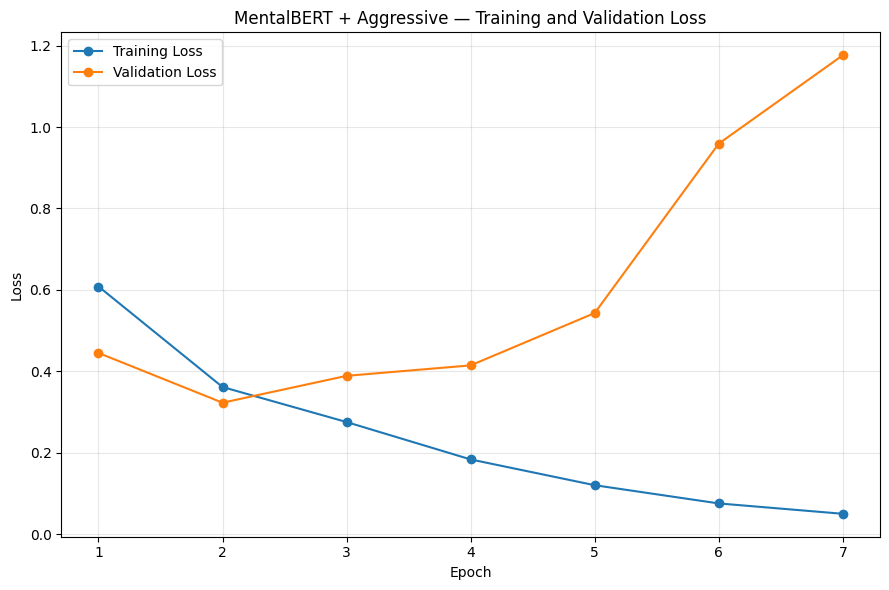

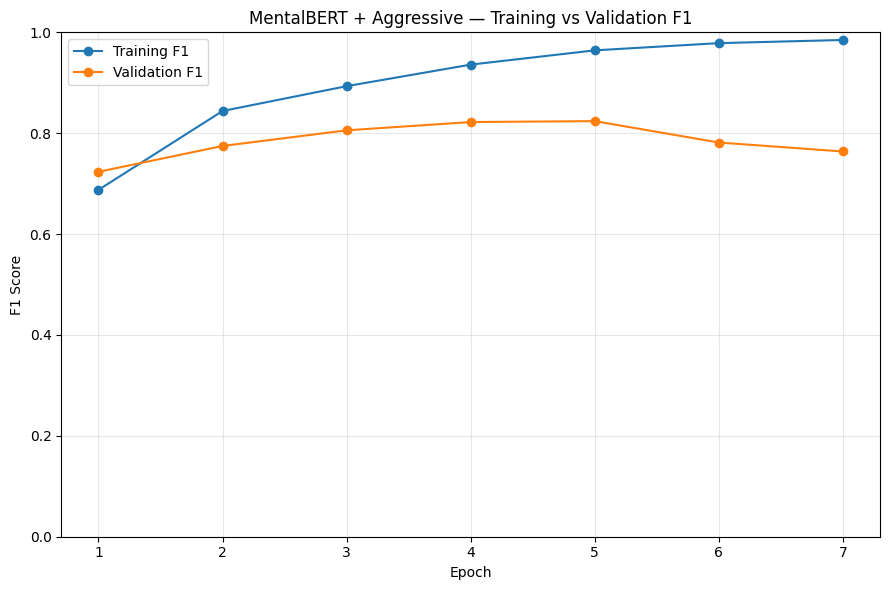

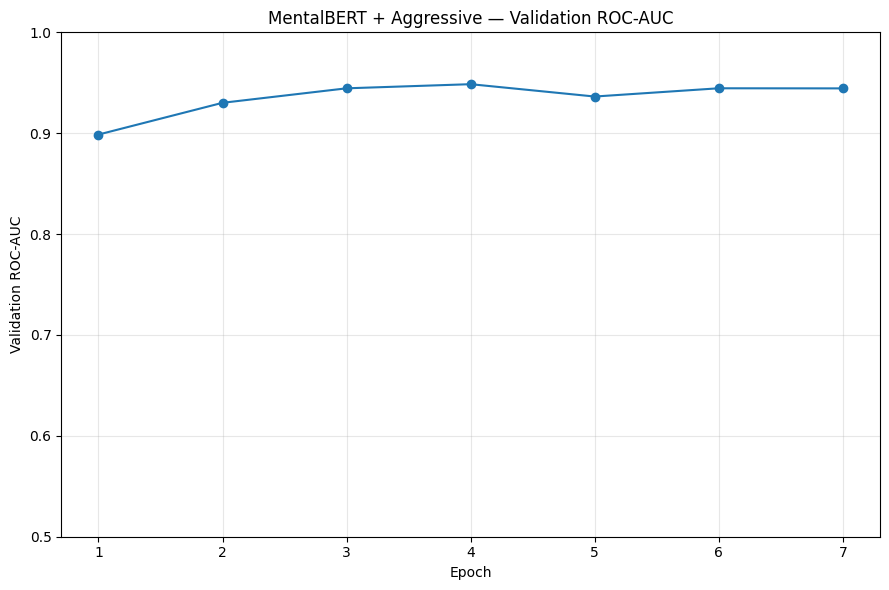

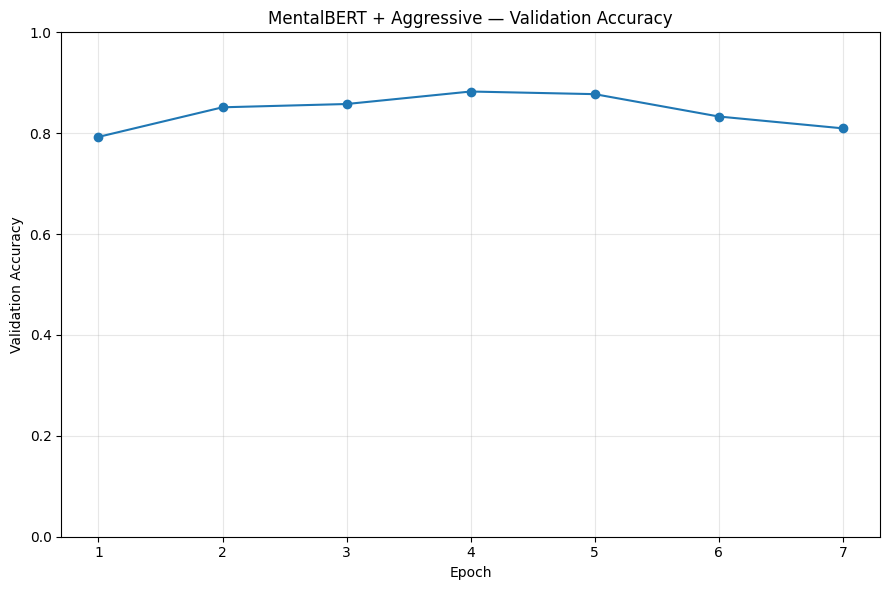

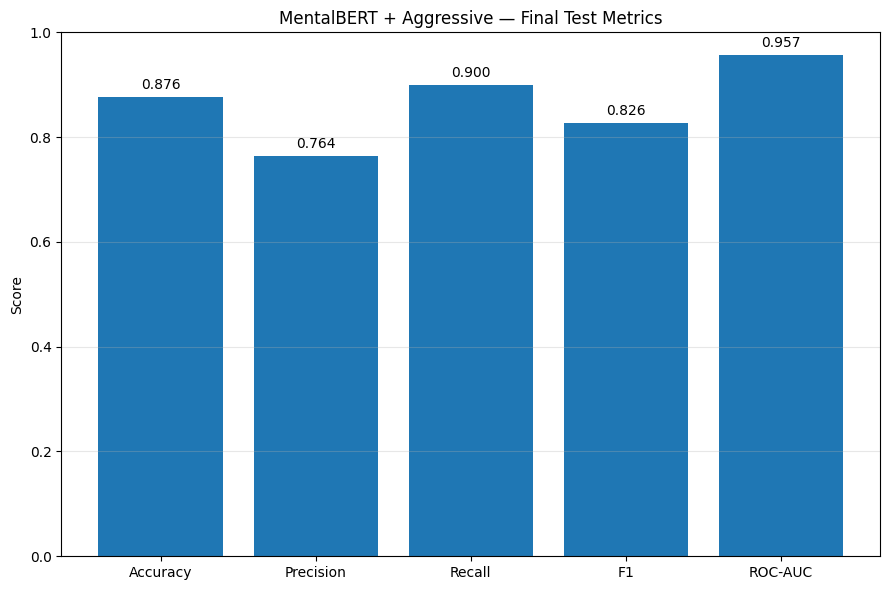

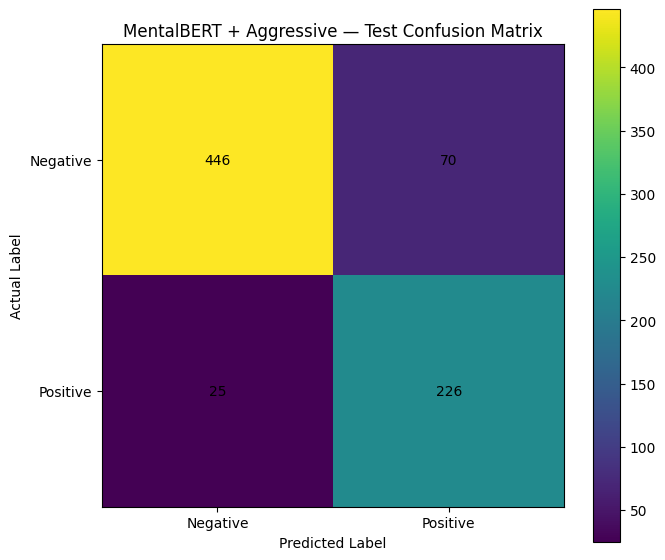

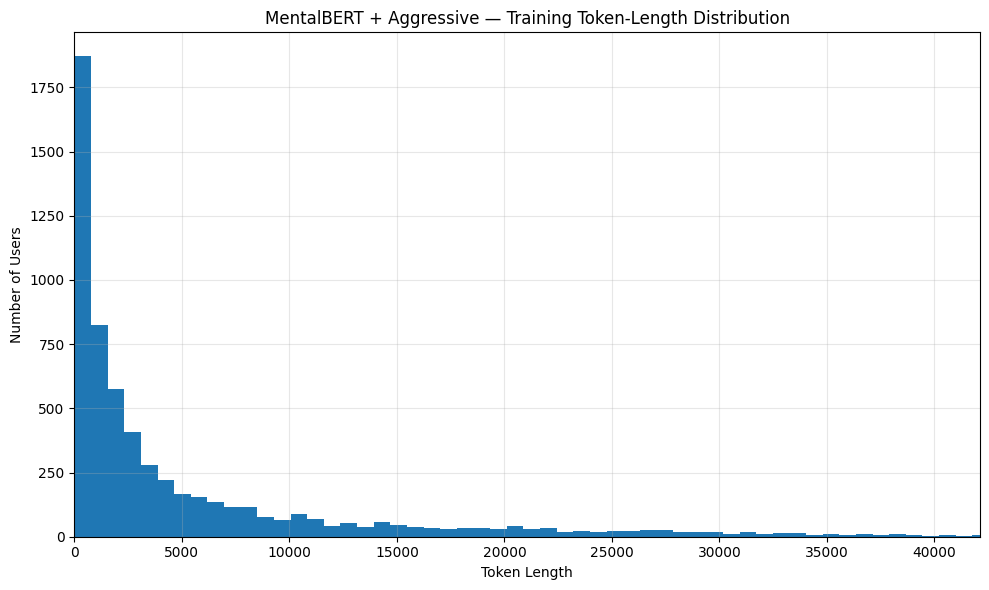


TOKEN-LENGTH / CONTEXT COVERAGE


,Split,Users,Mean Tokens,Median Tokens,Users <= 512,Coverage <= 512 (%),Users <= 4096,Coverage <= 4096 (%)
0,Train,6135,5904.68,1986,1493,24.34,4030,65.69
1,Validation,767,6256.66,1989,186,24.25,489,63.75
2,Test,767,6254.55,1957,194,25.29,504,65.71


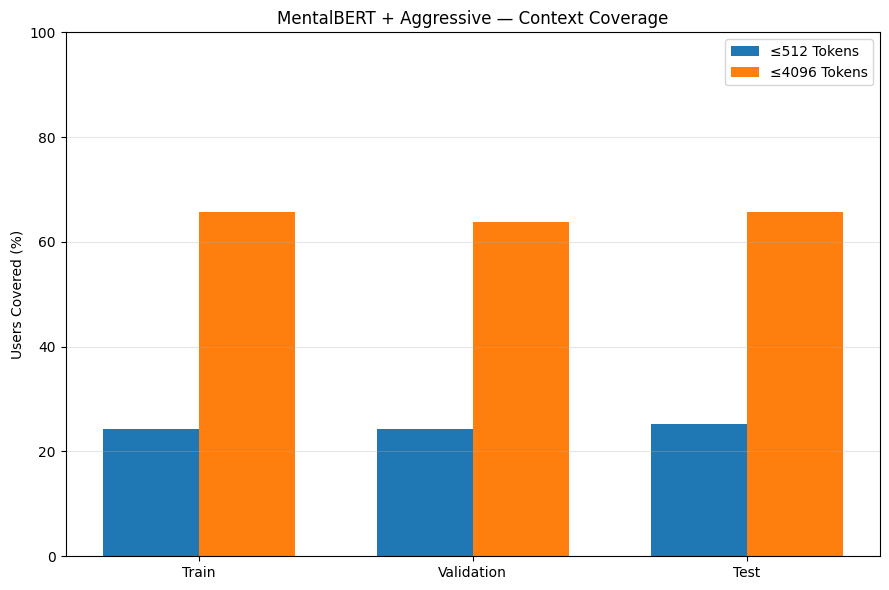

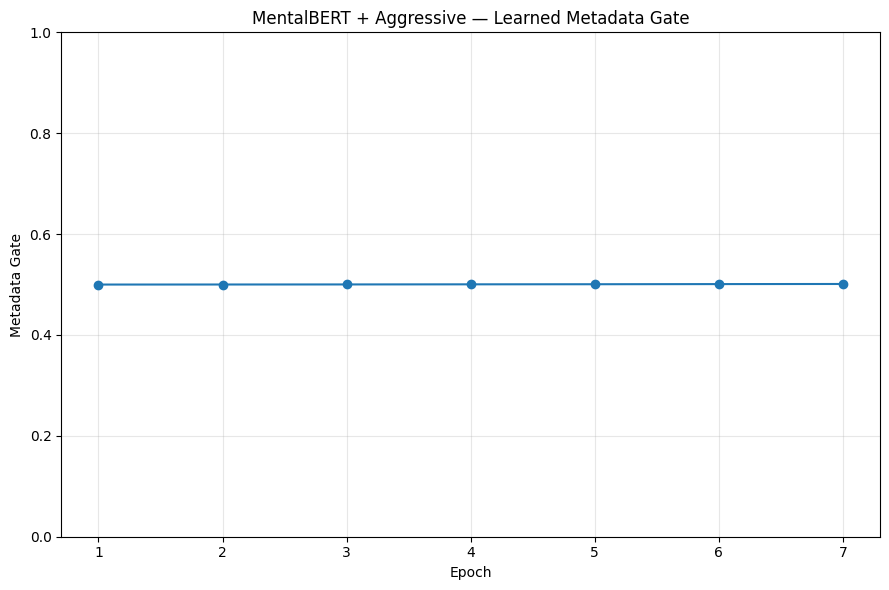

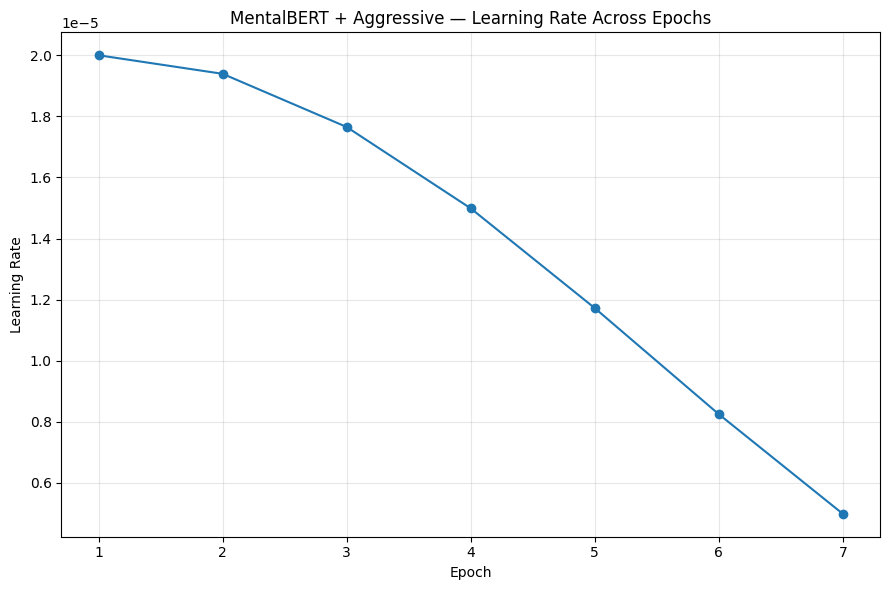


FINAL REPORT PACKAGE COMPLETE

Experiment:
MentalBERT + Aggressive

Final Test Metrics:
Accuracy : 87.61%
Precision: 76.35%
Recall   : 90.04%
F1       : 82.63%
ROC-AUC  : 95.71%

Best Epoch: 5
Best Validation F1: 82.40%

Figures saved: 10
Tables saved: 7

Report directory: /kaggle/working/mentalbert_aggressive_results/final_report
Excel workbook: /kaggle/working/mentalbert_aggressive_results/final_report/MentalBERT_Aggressive_Final_Report.xlsx

✓ FINAL REPORTING PACKAGE SAVED


In [17]:
# ============================================================
# FINAL REPORTING PACKAGE
# MENTALBERT + AGGRESSIVE
#
# THIS STRUCTURE WILL BE USED FOR EVERY EXPERIMENT
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("=" * 80)
print("MENTALBERT + AGGRESSIVE — FINAL REPORTING PACKAGE")
print("=" * 80)


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

REPORT_DIR = os.path.join(
    MENTAL_AGG_RESULT_DIR,
    "final_report"
)

FIGURE_DIR = os.path.join(
    REPORT_DIR,
    "figures"
)

TABLE_DIR = os.path.join(
    REPORT_DIR,
    "tables"
)

os.makedirs(
    REPORT_DIR,
    exist_ok=True
)

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)


# ============================================================
# 1. FINAL TEST METRICS TABLE
# ============================================================

final_metrics = pd.DataFrame([{

    "Experiment":
        "MentalBERT + Aggressive",

    "Model":
        "MentalBERT",

    "Cleaning":
        "Aggressive",

    "Context_Length":
        512,

    "Parameters_M":
        110.253,

    "Best_Epoch":
        best_epoch_loaded,

    "Best_Validation_F1":
        best_val_f1_loaded,

    "Test_Loss":
        test_loss,

    "Test_Accuracy":
        test_accuracy,

    "Test_Precision":
        test_precision,

    "Test_Recall":
        test_recall,

    "Test_F1":
        test_f1,

    "Test_ROC_AUC":
        test_roc_auc,

    "Metadata_Beta":
        metadata_beta,

    "Metadata_Gate":
        metadata_gate
}])


print()
print("=" * 80)
print("FINAL TEST METRICS")
print("=" * 80)

display(
    final_metrics.style.format({
        "Parameters_M": "{:.3f}",
        "Best_Validation_F1": "{:.4f}",
        "Test_Loss": "{:.4f}",
        "Test_Accuracy": "{:.4f}",
        "Test_Precision": "{:.4f}",
        "Test_Recall": "{:.4f}",
        "Test_F1": "{:.4f}",
        "Test_ROC_AUC": "{:.4f}",
        "Metadata_Beta": "{:.6f}",
        "Metadata_Gate": "{:.6f}"
    })
)


# ============================================================
# 2. FORMATTED PAPER-READY METRICS TABLE
# ============================================================

paper_metrics = pd.DataFrame([{

    "Model":
        "MentalBERT",

    "Cleaning":
        "Aggressive",

    "Accuracy (%)":
        test_accuracy * 100,

    "Precision (%)":
        test_precision * 100,

    "Recall (%)":
        test_recall * 100,

    "F1 (%)":
        test_f1 * 100,

    "ROC-AUC (%)":
        test_roc_auc * 100

}])


print()
print("=" * 80)
print("PAPER-READY TEST RESULTS")
print("=" * 80)

display(
    paper_metrics.style.format({
        "Accuracy (%)": "{:.2f}",
        "Precision (%)": "{:.2f}",
        "Recall (%)": "{:.2f}",
        "F1 (%)": "{:.2f}",
        "ROC-AUC (%)": "{:.2f}"
    })
)


# ============================================================
# 3. CONFUSION MATRIX
# ============================================================

cm_final = confusion_matrix(
    test_labels,
    test_predictions
)

cm_table = pd.DataFrame(
    cm_final,
    index=[
        "Actual Negative",
        "Actual Positive"
    ],
    columns=[
        "Predicted Negative",
        "Predicted Positive"
    ]
)

print()
print("=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

display(cm_table)


# ============================================================
# 4. CLASSIFICATION REPORT TABLE
# ============================================================

classification_dict = classification_report(
    test_labels,
    test_predictions,
    target_names=[
        "Negative",
        "Positive"
    ],
    output_dict=True,
    zero_division=0
)

classification_table = (
    pd.DataFrame(
        classification_dict
    )
    .transpose()
)

print()
print("=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

display(
    classification_table.style.format(
        "{:.4f}"
    )
)


# ============================================================
# 5. TRAINING HISTORY TABLE
# ============================================================

history_df = pd.DataFrame(
    history_mental_aggressive
)

print()
print("=" * 80)
print("TRAINING HISTORY")
print("=" * 80)

display(
    history_df
)


# ============================================================
# 6. BEST EPOCH SUMMARY
# ============================================================

best_history_row = history_df[
    history_df["epoch"]
    == best_epoch_loaded
].iloc[0]

best_epoch_table = pd.DataFrame([{

    "Best Epoch":
        best_epoch_loaded,

    "Train Loss":
        best_history_row["train_loss"],

    "Train Accuracy":
        best_history_row["train_accuracy"],

    "Train Precision":
        best_history_row["train_precision"],

    "Train Recall":
        best_history_row["train_recall"],

    "Train F1":
        best_history_row["train_f1"],

    "Validation Loss":
        best_history_row["val_loss"],

    "Validation Accuracy":
        best_history_row["val_accuracy"],

    "Validation Precision":
        best_history_row["val_precision"],

    "Validation Recall":
        best_history_row["val_recall"],

    "Validation F1":
        best_history_row["val_f1"],

    "Validation ROC-AUC":
        best_history_row["val_roc_auc"],

    "Metadata Gate":
        best_history_row["metadata_gate"]
}])


print()
print("=" * 80)
print("BEST EPOCH SUMMARY")
print("=" * 80)

display(
    best_epoch_table.style.format(
        "{:.4f}"
    )
)


# ============================================================
# 7. GRAPH — TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "MentalBERT + Aggressive — Training and Validation Loss"
)

plt.xticks(
    history_df["epoch"]
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "01_training_validation_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 8. GRAPH — TRAINING VS VALIDATION F1
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_f1"],
    marker="o",
    label="Training F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.title(
    "MentalBERT + Aggressive — Training vs Validation F1"
)

plt.xticks(
    history_df["epoch"]
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "02_training_validation_f1.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9. GRAPH — VALIDATION ROC-AUC
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Validation ROC-AUC")

plt.title(
    "MentalBERT + Aggressive — Validation ROC-AUC"
)

plt.xticks(
    history_df["epoch"]
)

plt.ylim(
    0.5,
    1.0
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "03_validation_roc_auc.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. GRAPH — VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.title(
    "MentalBERT + Aggressive — Validation Accuracy"
)

plt.xticks(
    history_df["epoch"]
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "04_validation_accuracy.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. GRAPH — FINAL TEST METRICS
# ============================================================

test_metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

test_metric_values = [
    test_accuracy,
    test_precision,
    test_recall,
    test_f1,
    test_roc_auc
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    test_metric_names,
    test_metric_values
)

plt.ylabel("Score")
plt.ylim(
    0,
    1
)

plt.title(
    "MentalBERT + Aggressive — Final Test Metrics"
)

plt.grid(
    axis="y",
    alpha=0.3
)

for bar, value in zip(
    bars,
    test_metric_values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "05_final_test_metrics.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. GRAPH — CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(7, 6))

plt.imshow(
    cm_final,
    interpolation="nearest"
)

plt.title(
    "MentalBERT + Aggressive — Test Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

threshold = (
    cm_final.max()
    / 2.0
)

for i in range(
    cm_final.shape[0]
):

    for j in range(
        cm_final.shape[1]
    ):

        plt.text(
            j,
            i,
            str(cm_final[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "06_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. TOKEN LENGTH DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    train_mental_aggressive_token_lengths,
    bins=100
)

plt.xlabel(
    "Token Length"
)

plt.ylabel(
    "Number of Users"
)

plt.title(
    "MentalBERT + Aggressive — Training Token-Length Distribution"
)

plt.xlim(
    0,
    np.percentile(
        train_mental_aggressive_token_lengths,
        99
    )
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "07_training_token_length_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. TOKEN COVERAGE TABLE
# ============================================================

token_coverage_table = pd.DataFrame([

    {
        "Split":
            "Train",

        "Users":
            len(
                train_mental_aggressive_token_lengths
            ),

        "Mean Tokens":
            np.mean(
                train_mental_aggressive_token_lengths
            ),

        "Median Tokens":
            np.median(
                train_mental_aggressive_token_lengths
            ),

        "Users <= 512":
            np.sum(
                train_mental_aggressive_token_lengths
                <= 512
            ),

        "Coverage <= 512 (%)":
            100 * np.mean(
                train_mental_aggressive_token_lengths
                <= 512
            ),

        "Users <= 4096":
            np.sum(
                train_mental_aggressive_token_lengths
                <= 4096
            ),

        "Coverage <= 4096 (%)":
            100 * np.mean(
                train_mental_aggressive_token_lengths
                <= 4096
            )
    },

    {
        "Split":
            "Validation",

        "Users":
            len(
                val_mental_aggressive_token_lengths
            ),

        "Mean Tokens":
            np.mean(
                val_mental_aggressive_token_lengths
            ),

        "Median Tokens":
            np.median(
                val_mental_aggressive_token_lengths
            ),

        "Users <= 512":
            np.sum(
                val_mental_aggressive_token_lengths
                <= 512
            ),

        "Coverage <= 512 (%)":
            100 * np.mean(
                val_mental_aggressive_token_lengths
                <= 512
            ),

        "Users <= 4096":
            np.sum(
                val_mental_aggressive_token_lengths
                <= 4096
            ),

        "Coverage <= 4096 (%)":
            100 * np.mean(
                val_mental_aggressive_token_lengths
                <= 4096
            )
    },

    {
        "Split":
            "Test",

        "Users":
            len(
                test_mental_aggressive_token_lengths
            ),

        "Mean Tokens":
            np.mean(
                test_mental_aggressive_token_lengths
            ),

        "Median Tokens":
            np.median(
                test_mental_aggressive_token_lengths
            ),

        "Users <= 512":
            np.sum(
                test_mental_aggressive_token_lengths
                <= 512
            ),

        "Coverage <= 512 (%)":
            100 * np.mean(
                test_mental_aggressive_token_lengths
                <= 512
            ),

        "Users <= 4096":
            np.sum(
                test_mental_aggressive_token_lengths
                <= 4096
            ),

        "Coverage <= 4096 (%)":
            100 * np.mean(
                test_mental_aggressive_token_lengths
                <= 4096
            )
    }
])

print()
print("=" * 80)
print("TOKEN-LENGTH / CONTEXT COVERAGE")
print("=" * 80)

display(
    token_coverage_table.style.format({
        "Mean Tokens": "{:.2f}",
        "Median Tokens": "{:.0f}",
        "Coverage <= 512 (%)": "{:.2f}",
        "Coverage <= 4096 (%)": "{:.2f}"
    })
)


# ============================================================
# 15. 512 vs 4096 CONTEXT COVERAGE GRAPH
# ============================================================

coverage_plot = token_coverage_table[
    [
        "Split",
        "Coverage <= 512 (%)",
        "Coverage <= 4096 (%)"
    ]
]

x = np.arange(
    len(coverage_plot)
)

width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    coverage_plot[
        "Coverage <= 512 (%)"
    ],
    width,
    label="≤512 Tokens"
)

plt.bar(
    x + width / 2,
    coverage_plot[
        "Coverage <= 4096 (%)"
    ],
    width,
    label="≤4096 Tokens"
)

plt.xticks(
    x,
    coverage_plot["Split"]
)

plt.ylabel(
    "Users Covered (%)"
)

plt.ylim(
    0,
    100
)

plt.title(
    "MentalBERT + Aggressive — Context Coverage"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "08_context_coverage.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 16. METADATA GATE OVER EPOCHS
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["metadata_gate"],
    marker="o"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Metadata Gate"
)

plt.title(
    "MentalBERT + Aggressive — Learned Metadata Gate"
)

plt.xticks(
    history_df["epoch"]
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "09_metadata_gate.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 17. TRAINING LEARNING RATE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["learning_rate"],
    marker="o"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Learning Rate"
)

plt.title(
    "MentalBERT + Aggressive — Learning Rate Across Epochs"
)

plt.xticks(
    history_df["epoch"]
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "10_learning_rate.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18. SAVE TABLES
# ============================================================

final_metrics.to_csv(
    os.path.join(
        TABLE_DIR,
        "01_final_metrics.csv"
    ),
    index=False
)

paper_metrics.to_csv(
    os.path.join(
        TABLE_DIR,
        "02_paper_ready_metrics.csv"
    ),
    index=False
)

cm_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "03_confusion_matrix.csv"
    )
)

classification_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "04_classification_report.csv"
    )
)

history_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "05_training_history.csv"
    ),
    index=False
)

best_epoch_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "06_best_epoch_summary.csv"
    ),
    index=False
)

token_coverage_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "07_token_context_coverage.csv"
    ),
    index=False
)


# ============================================================
# 19. EXCEL WORKBOOK
# ============================================================

excel_path = os.path.join(
    REPORT_DIR,
    "MentalBERT_Aggressive_Final_Report.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    final_metrics.to_excel(
        writer,
        sheet_name="Final Metrics",
        index=False
    )

    paper_metrics.to_excel(
        writer,
        sheet_name="Paper Metrics",
        index=False
    )

    cm_table.to_excel(
        writer,
        sheet_name="Confusion Matrix"
    )

    classification_table.to_excel(
        writer,
        sheet_name="Classification Report"
    )

    history_df.to_excel(
        writer,
        sheet_name="Training History",
        index=False
    )

    best_epoch_table.to_excel(
        writer,
        sheet_name="Best Epoch",
        index=False
    )

    token_coverage_table.to_excel(
        writer,
        sheet_name="Token Coverage",
        index=False
    )


# ============================================================
# 20. REPORT INDEX
# ============================================================

figure_files = sorted([
    f
    for f in os.listdir(FIGURE_DIR)
    if f.endswith(".png")
])

table_files = sorted([
    f
    for f in os.listdir(TABLE_DIR)
    if f.endswith(".csv")
])

report_index = pd.DataFrame({

    "Type":
        ["Figure"] * len(figure_files)
        + ["Table"] * len(table_files),

    "File":
        figure_files
        + table_files
})

report_index.to_csv(
    os.path.join(
        REPORT_DIR,
        "report_index.csv"
    ),
    index=False
)


# ============================================================
# 21. FINAL REPORT SUMMARY
# ============================================================

print()
print("=" * 80)
print("FINAL REPORT PACKAGE COMPLETE")
print("=" * 80)

print()
print("Experiment:")
print("MentalBERT + Aggressive")

print()
print("Final Test Metrics:")

print(
    f"Accuracy : {test_accuracy * 100:.2f}%"
)

print(
    f"Precision: {test_precision * 100:.2f}%"
)

print(
    f"Recall   : {test_recall * 100:.2f}%"
)

print(
    f"F1       : {test_f1 * 100:.2f}%"
)

print(
    f"ROC-AUC  : {test_roc_auc * 100:.2f}%"
)

print()
print(
    "Best Epoch:",
    best_epoch_loaded
)

print(
    "Best Validation F1:",
    f"{best_val_f1_loaded * 100:.2f}%"
)

print()
print(
    "Figures saved:",
    len(figure_files)
)

print(
    "Tables saved:",
    len(table_files)
)

print()
print(
    "Report directory:",
    REPORT_DIR
)

print(
    "Excel workbook:",
    excel_path
)

print()
print("=" * 80)
print("✓ FINAL REPORTING PACKAGE SAVED")
print("=" * 80)

In [20]:
# ============================================================
# CELL 14 — MENTALBERT + AGGRESSIVE
# TABLES ONLY
# ============================================================

import os
import json
import numpy as np
import pandas as pd

TABLE_DIR = os.path.join(
    MENTAL_AGG_RESULT_DIR,
    "tables"
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)

print("=" * 60)
print("MENTALBERT + AGGRESSIVE — TABLES")
print("=" * 60)

# Load results
metrics_df = pd.read_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_test_metrics.csv"
    )
)

history_df = pd.read_csv(
    os.path.join(
        MENTAL_AGG_RESULT_DIR,
        "mentalbert_aggressive_training_history.csv"
    )
)

# ============================================================
# FINAL RESULTS TABLE
# ============================================================

best_epoch = int(
    metrics_df.loc[
        0,
        "best_epoch"
    ]
)

best_epoch_row = history_df[
    history_df["epoch"] == best_epoch
].iloc[0]

results_table = pd.DataFrame({
    "Model": ["MentalBERT"],
    "Cleaning": ["Aggressive"],
    "Train Accuracy": [
        best_epoch_row["train_accuracy"] * 100
    ],
    "Validation Accuracy": [
        best_epoch_row["val_accuracy"] * 100
    ],
    "Test Accuracy": [
        metrics_df.loc[
            0,
            "test_accuracy"
        ] * 100
    ],
    "Precision": [
        metrics_df.loc[
            0,
            "test_precision"
        ] * 100
    ],
    "Recall": [
        metrics_df.loc[
            0,
            "test_recall"
        ] * 100
    ],
    "F1-Score": [
        metrics_df.loc[
            0,
            "test_f1"
        ] * 100
    ],
    "ROC-AUC": [
        metrics_df.loc[
            0,
            "test_roc_auc"
        ] * 100
    ]
}).round(2)

print()
print("=" * 60)
print("FINAL RESULTS TABLE")
print("=" * 60)

print(
    results_table.to_string(
        index=False
    )
)

results_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "mentalbert_aggressive_results_table.csv"
    ),
    index=False
)

# Save training history
history_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "mentalbert_aggressive_training_history_table.csv"
    ),
    index=False
)

# ============================================================
# SUMMARY FILE
# ============================================================

with open(
    os.path.join(
        TABLE_DIR,
        "mentalbert_aggressive_summary.txt"
    ),
    "w"
) as f:

    f.write(
        "MENTALBERT + AGGRESSIVE — FINAL RESULTS\n"
    )

    f.write(
        "========================================\n"
    )

    f.write(
        f"Train Accuracy      : "
        f"{best_epoch_row['train_accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Validation Accuracy : "
        f"{best_epoch_row['val_accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Test Accuracy       : "
        f"{metrics_df.loc[0, 'test_accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Precision            : "
        f"{metrics_df.loc[0, 'test_precision'] * 100:.2f}%\n"
    )

    f.write(
        f"Recall               : "
        f"{metrics_df.loc[0, 'test_recall'] * 100:.2f}%\n"
    )

    f.write(
        f"F1-Score             : "
        f"{metrics_df.loc[0, 'test_f1'] * 100:.2f}%\n"
    )

    f.write(
        f"ROC-AUC              : "
        f"{metrics_df.loc[0, 'test_roc_auc'] * 100:.2f}%\n"
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 14 COMPLETE")
print("=" * 60)

print(
    "✓ Final results table saved"
)

print(
    "✓ Train / Validation / Test accuracies included"
)

print(
    "✓ Training history table saved"
)

print(
    "✓ Summary file saved"
)

print()
print(
    "Tables:",
    TABLE_DIR
)

MENTALBERT + AGGRESSIVE — TABLES

FINAL RESULTS TABLE
     Model   Cleaning  Train Accuracy  Validation Accuracy  Test Accuracy  Precision  Recall  F1-Score  ROC-AUC
MentalBERT Aggressive           96.47                87.74          87.61      76.35   90.04     82.63    95.71

CELL 14 COMPLETE
✓ Final results table saved
✓ Train / Validation / Test accuracies included
✓ Training history table saved
✓ Summary file saved

Tables: /kaggle/working/mentalbert_aggressive_results/tables


t-SNE REPRESENTATION ANALYSIS
MENTALBERT + AGGRESSIVE

Extracting fused model representations...
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION
Representation shape: (767, 832)
Number of test users: 767
Representation dimensions: 832
Negative users: 516
Positive users: 251

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 99.06%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


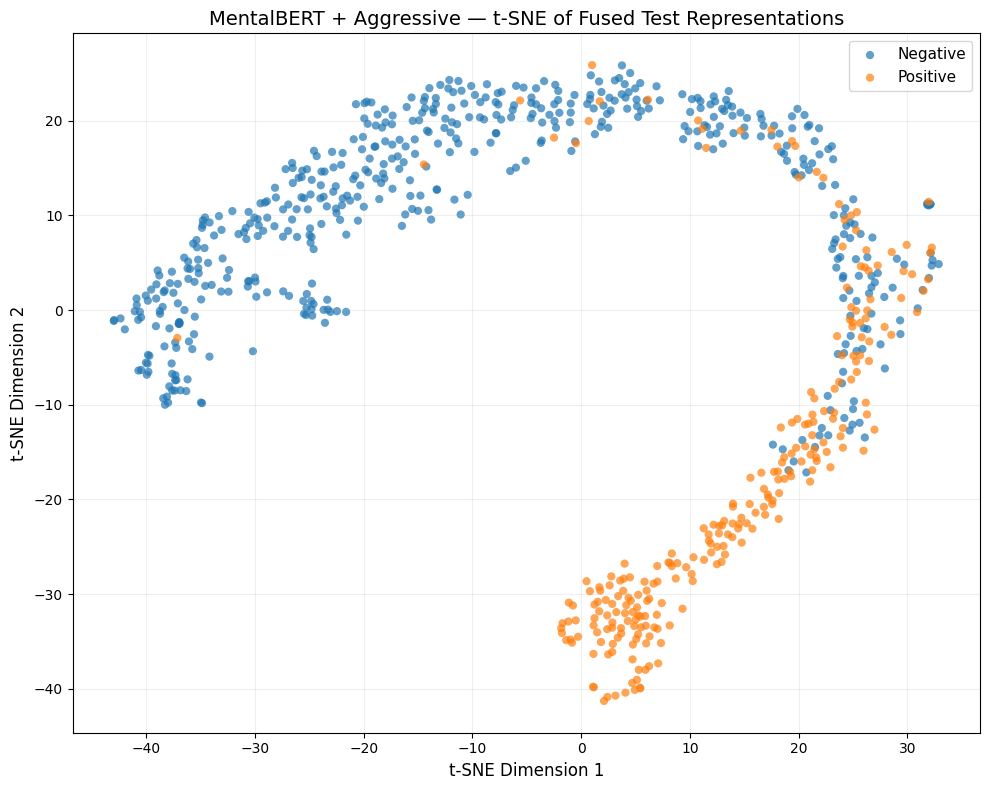


t-SNE ANALYSIS COMPLETE
✓ Fused representation extracted
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ Coordinates saved:
/kaggle/working/mentalbert_aggressive_results/explainability/tsne/mentalbert_aggressive_tsne_coordinates.csv
✓ Graph saved:
/kaggle/working/mentalbert_aggressive_results/explainability/tsne/mentalbert_aggressive_tsne.png
✓ Graph displayed above
✓ Configuration saved


In [21]:
# ============================================================
# EXPLAINABILITY — CELL 1
# MENTALBERT + AGGRESSIVE
# t-SNE: FUSED REPRESENTATION → PCA → t-SNE
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("MENTALBERT + AGGRESSIVE")
print("=" * 70)

# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42
PCA_COMPONENTS = 50
TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    MENTAL_AGG_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_mental_aggressive.eval()

# ============================================================
# EXTRACT FUSED REPRESENTATIONS
# ============================================================

fused_representations = []
test_labels = []

print()
print(
    "Extracting fused model representations..."
)

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader_mental_aggressive,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_mental_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # ----------------------------------------------------
        # ACTUAL OUTPUT NAMES FROM MENTALBERT MODEL
        # ----------------------------------------------------

        text_representation = output[
            "text_representation"
        ]

        metadata_representation = output[
            "metadata_representation"
        ]

        # ----------------------------------------------------
        # SAME LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            model_mental_aggressive.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(
                test_loader_mental_aggressive
            )
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/"
                f"{len(test_loader_mental_aggressive)}"
            )

# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)

# ============================================================
# INTEGRITY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION")
print("=" * 70)

print(
    "Representation shape:",
    fused_representations.shape
)

print(
    "Number of test users:",
    len(test_labels)
)

print(
    "Representation dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert np.isfinite(
    fused_representations
).all()

# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

explained_variance = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{explained_variance * 100:.2f}%"
)

# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)

# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "mentalbert_aggressive_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)

# ============================================================
# PUBLICATION-QUALITY PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Negative",
    edgecolors="none"
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Positive",
    edgecolors="none"
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "MentalBERT + Aggressive — "
    "t-SNE of Fused Test Representations",
    fontsize=14
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "mentalbert_aggressive_tsne.png"
)

# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Aggressive",

    "dataset":
        "Held-out test set",

    "test_users":
        int(
            len(test_labels)
        ),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            explained_variance
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED

}

with open(
    os.path.join(
        TSNE_DIR,
        "mentalbert_aggressive_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )

# ============================================================
# FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Fused representation extracted"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ Graph displayed above"
)

print(
    "✓ Configuration saved"
)

SHAP ANALYSIS
MENTALBERT + AGGRESSIVE

Total metadata features: 53

SHAP background samples: 50
Background dimensions: 53

SHAP test samples: 100
Negative: 50
Positive: 50

✓ MentalBERT model set to evaluation mode
✓ No parameters will be updated

COMPUTING SHAP VALUES
Explained 1/100 test users
Explained 10/100 test users
Explained 20/100 test users
Explained 30/100 test users
Explained 40/100 test users
Explained 50/100 test users
Explained 60/100 test users
Explained 70/100 test users
Explained 80/100 test users
Explained 90/100 test users
Explained 100/100 test users

SHAP RESULT SUMMARY
SHAP matrix: (100, 53)
Metadata matrix: (100, 53)

TOP 20 SHAP FEATURES
            feature  mean_abs_shap  mean_signed_shap
  lexical_diversity       0.000483      9.176744e-05
    uppercase_ratio       0.000390     -2.466244e-05
       lda_topic_14       0.000379     -4.013531e-05
        lda_topic_2       0.000361      5.508660e-05
       lda_topic_17       0.000304      8.830488e-05
      emoti

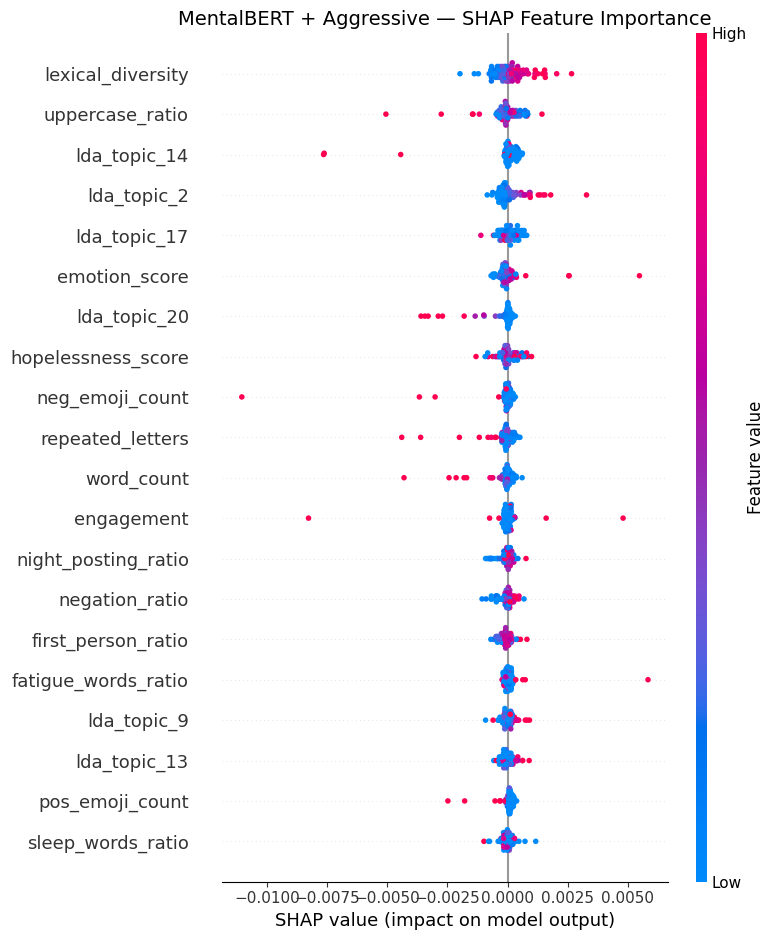

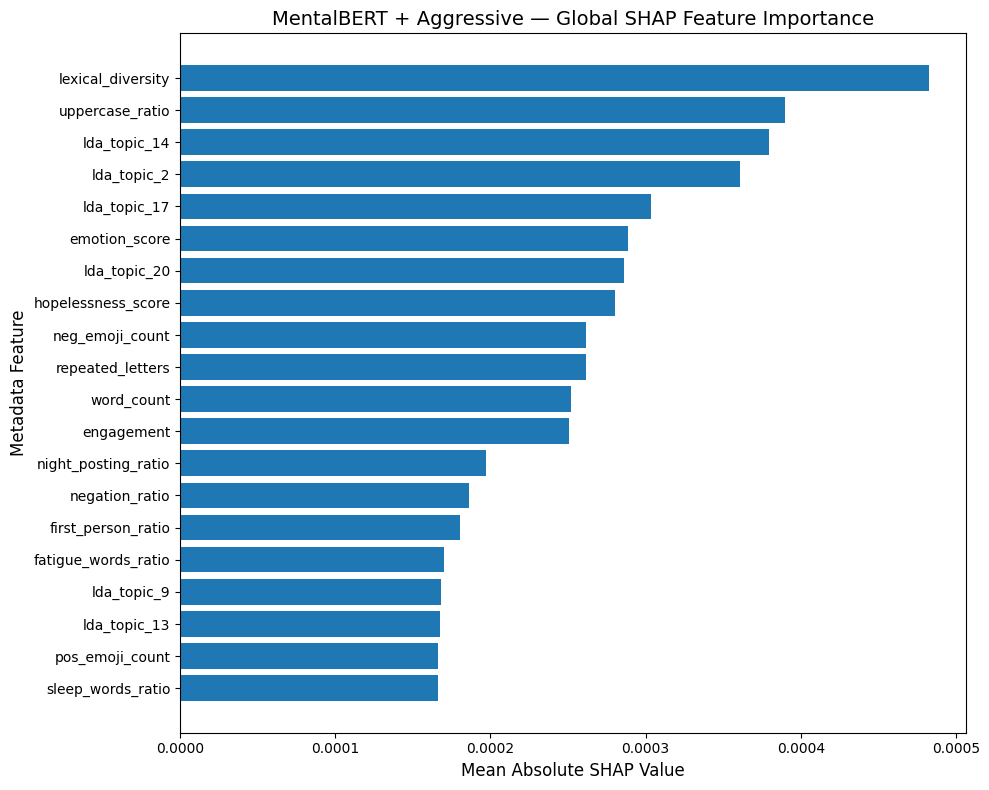


SHAP ANALYSIS COMPLETE
✓ 53 metadata features explained
✓ 100 fixed test users explained
✓ 50 negative + 50 positive
✓ Training-only background used
✓ Positive-class logit explained
✓ MentalBERT weights unchanged
✓ SHAP beeswarm saved and displayed
✓ SHAP bar plot saved and displayed
✓ SHAP values saved
✓ Feature importance ranking saved
✓ Configuration saved

SHAP output directory: /kaggle/working/mentalbert_aggressive_results/explainability/shap


In [24]:
# ============================================================
# EXPLAINABILITY — SHAP
# MENTALBERT + AGGRESSIVE
# GLOBAL METADATA FEATURE EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("MENTALBERT + AGGRESSIVE")
print("=" * 70)

# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(
    SHAP_SEED
)

torch.manual_seed(
    SHAP_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    MENTAL_AGG_RESULT_DIR,
    "explainability"
)

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)

# ============================================================
# FEATURE NAMES
# ============================================================

feature_names = list(
    mental_aggressive_metadata_features
)

assert len(feature_names) == 53
assert len(feature_names) == 53

print()
print(
    "Total metadata features:",
    len(feature_names)
)

# ============================================================
# FIXED BACKGROUND DATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (
    train_dataset_mental_aggressive.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
    .to(device)
)

print()
print(
    "SHAP background samples:",
    background_metadata.shape[0]
)

print(
    "Background dimensions:",
    background_metadata.shape[1]
)

assert background_metadata.shape[1] == 53

# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels_tensor = (
    test_dataset_mental_aggressive.labels
    .detach()
    .cpu()
)

negative_indices = torch.where(
    test_labels_tensor == 0
)[0].numpy()

positive_indices = torch.where(
    test_labels_tensor == 1
)[0].numpy()

assert (
    len(negative_indices)
    >= SHAP_TEST_SIZE_PER_CLASS
)

assert (
    len(positive_indices)
    >= SHAP_TEST_SIZE_PER_CLASS
)

shap_negative_indices = (
    negative_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_positive_indices = (
    positive_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_test_indices = np.concatenate(
    [
        shap_negative_indices,
        shap_positive_indices
    ]
)

print()
print(
    "SHAP test samples:",
    len(shap_test_indices)
)

print(
    "Negative:",
    len(shap_negative_indices)
)

print(
    "Positive:",
    len(shap_positive_indices)
)

# ============================================================
# MODEL WRAPPER
# ============================================================
# Explains metadata while keeping each user's
# Transformer text representation fixed.
# No model parameters are changed.

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_input_ids,
        fixed_attention_mask
    ):

        super().__init__()

        self.base_model = base_model

        self.fixed_input_ids = (
            fixed_input_ids
            .to(device)
        )

        self.fixed_attention_mask = (
            fixed_attention_mask
            .to(device)
        )

    def forward(
        self,
        metadata
    ):

        batch_size = (
            metadata.size(0)
        )

        input_ids = (
            self.fixed_input_ids
            .expand(
                batch_size,
                -1
            )
        )

        attention_mask = (
            self.fixed_attention_mask
            .expand(
                batch_size,
                -1
            )
        )

        output = self.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # Positive/depression class logit
        positive_logit = output[
            "logits"
        ][:, 1:2]

        return positive_logit


# ============================================================
# MODEL PREPARATION
# ============================================================

model_mental_aggressive.eval()

for parameter in (
    model_mental_aggressive.parameters()
):

    parameter.requires_grad = False

print()
print(
    "✓ MentalBERT model set to evaluation mode"
)

print(
    "✓ No parameters will be updated"
)

# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_values = []
all_metadata_values = []
all_explained_labels = []

print()
print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)

for count, test_index in enumerate(
    shap_test_indices,
    start=1
):

    sample = test_dataset_mental_aggressive[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
    )

    metadata_sample = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    label = int(
        sample["labels"].item()
    )

    # --------------------------------------------------------
    # User-specific wrapper
    # Text representation remains fixed for this user.
    # --------------------------------------------------------

    wrapper = MetadataSHAPWrapper(
        model_mental_aggressive,
        input_ids,
        attention_mask
    ).to(device)

    wrapper.eval()

    # --------------------------------------------------------
    # Gradient-based SHAP
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )

    shap_result = explainer.shap_values(
        metadata_sample
    )

    # --------------------------------------------------------
    # Handle SHAP version-dependent output format
    # --------------------------------------------------------

    if isinstance(
        shap_result,
        list
    ):

        shap_array = np.asarray(
            shap_result[0]
        )

    else:

        shap_array = np.asarray(
            shap_result
        )

    shap_array = np.squeeze(
        shap_array
    )

    assert shap_array.shape == (
        53,
    )

    all_shap_values.append(
        shap_array
    )

    all_metadata_values.append(
        metadata_sample
        .detach()
        .cpu()
        .numpy()
        .squeeze(0)
    )

    all_explained_labels.append(
        label
    )

    if (
        count == 1
        or count % 10 == 0
        or count == len(shap_test_indices)
    ):

        print(
            f"Explained "
            f"{count}/{len(shap_test_indices)} "
            f"test users"
        )

# ============================================================
# COMBINE RESULTS
# ============================================================

all_shap_values = np.vstack(
    all_shap_values
)

all_metadata_values = np.vstack(
    all_metadata_values
)

all_explained_labels = np.array(
    all_explained_labels
)

print()
print("=" * 70)
print("SHAP RESULT SUMMARY")
print("=" * 70)

print(
    "SHAP matrix:",
    all_shap_values.shape
)

print(
    "Metadata matrix:",
    all_metadata_values.shape
)

assert all_shap_values.shape == (
    len(shap_test_indices),
    53
)

assert all_metadata_values.shape == (
    len(shap_test_indices),
    53
)

assert np.isfinite(
    all_shap_values
).all()

# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(all_shap_values),
    axis=0
)

mean_signed_shap = np.mean(
    all_shap_values,
    axis=0
)

feature_importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "mean_abs_shap":
        mean_abs_shap,

    "mean_signed_shap":
        mean_signed_shap

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print()
print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(
    feature_importance_df
    .head(SHAP_TOP_FEATURES)
    .to_string(
        index=False
    )
)

# ============================================================
# SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

shap_values_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_aggressive_shap_values.csv"
    ),
    index=False
)

# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_aggressive_shap_feature_importance.csv"
    ),
    index=False
)

# ============================================================
# SAVE EXPLAINED USER INFORMATION
# ============================================================

explained_users_df = pd.DataFrame({

    "test_index":
        shap_test_indices,

    "label":
        all_explained_labels

})

explained_users_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_aggressive_shap_test_users.csv"
    ),
    index=False
)

# ============================================================
# SHAP BEESWARM — PAPER FIGURE
# ============================================================

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    all_shap_values,
    all_metadata_values,
    feature_names=feature_names,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.title(
    "MentalBERT + Aggressive — "
    "SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_beeswarm_path = os.path.join(
    SHAP_DIR,
    "mentalbert_aggressive_shap_beeswarm.png"
)

plt.savefig(
    shap_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SHAP BAR — PAPER FIGURE
# ============================================================

top_features = (
    feature_importance_df
    .head(SHAP_TOP_FEATURES)
    .iloc[::-1]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Metadata Feature",
    fontsize=12
)

plt.title(
    "MentalBERT + Aggressive — "
    "Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_bar_path = os.path.join(
    SHAP_DIR,
    "mentalbert_aggressive_shap_bar.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

shap_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Aggressive",

    "dataset":
        "Held-out test set",

    "total_metadata_features":
        53,

    "background_samples":
        SHAP_BACKGROUND_SIZE,

    "test_samples_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_explained_test_users":
        len(shap_test_indices),

    "target":
        "Positive/depression class logit",

    "explainer":
        "SHAP GradientExplainer",

    "text_representation":
        "Fixed for each explained user",

    "random_seed":
        SHAP_SEED,

    "top_features_displayed":
        SHAP_TOP_FEATURES

}

with open(
    os.path.join(
        SHAP_DIR,
        "mentalbert_aggressive_shap_config.json"
    ),
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ 53 metadata features explained"
)

print(
    "✓ 100 fixed test users explained"
)

print(
    "✓ 50 negative + 50 positive"
)

print(
    "✓ Training-only background used"
)

print(
    "✓ Positive-class logit explained"
)

print(
    "✓ MentalBERT weights unchanged"
)

print(
    "✓ SHAP beeswarm saved and displayed"
)

print(
    "✓ SHAP bar plot saved and displayed"
)

print(
    "✓ SHAP values saved"
)

print(
    "✓ Feature importance ranking saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

GRAD-CAM ANALYSIS
MENTALBERT + AGGRESSIVE

✓ MentalBERT model loaded
✓ Evaluation mode enabled
✓ All model parameters remain frozen

FIXED REPRESENTATIVE TEST CASES
TP: test index = 1 | true = 1 | pred = 1 | probability = 0.9987
TN: test index = 2 | true = 0 | pred = 0 | probability = 0.0065
FP: test index = 0 | true = 0 | pred = 1 | probability = 0.9967
FN: test index = 68 | true = 1 | pred = 0 | probability = 0.0074

GENERATING GRAD-CAM EXPLANATIONS

Processing TP (test index 1)...
✓ TP Grad-CAM complete

Processing TN (test index 2)...
✓ TN Grad-CAM complete

Processing FP (test index 0)...
✓ FP Grad-CAM complete

Processing FN (test index 68)...
✓ FN Grad-CAM complete

GRAD-CAM TOKEN IMPORTANCE


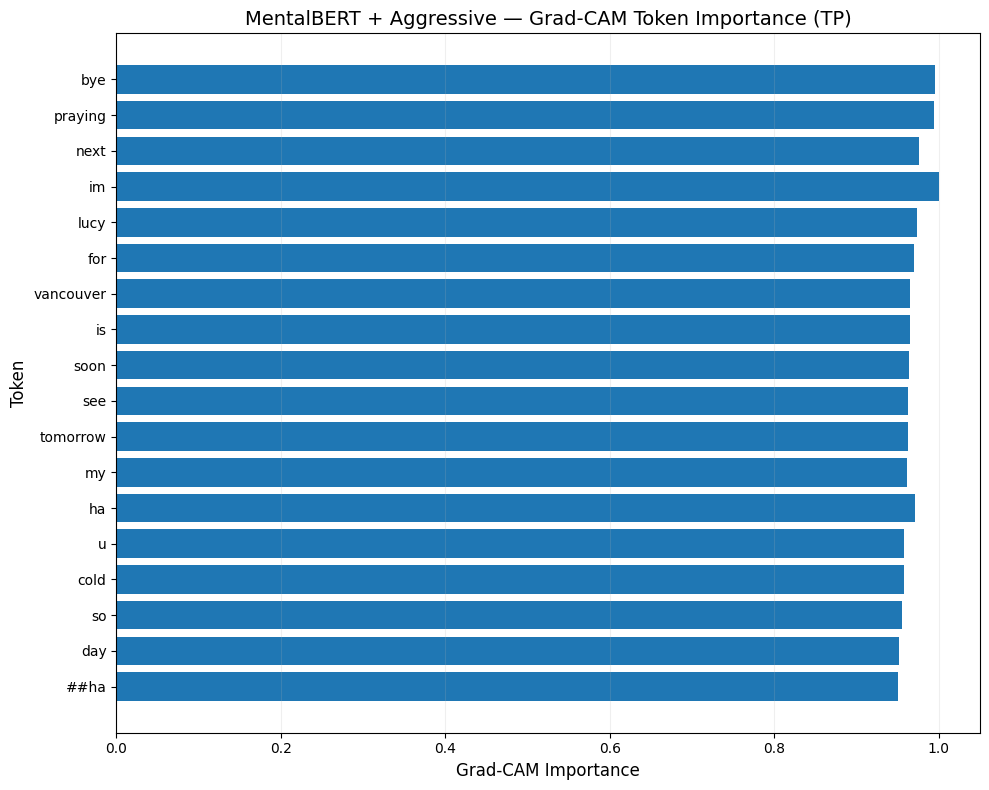

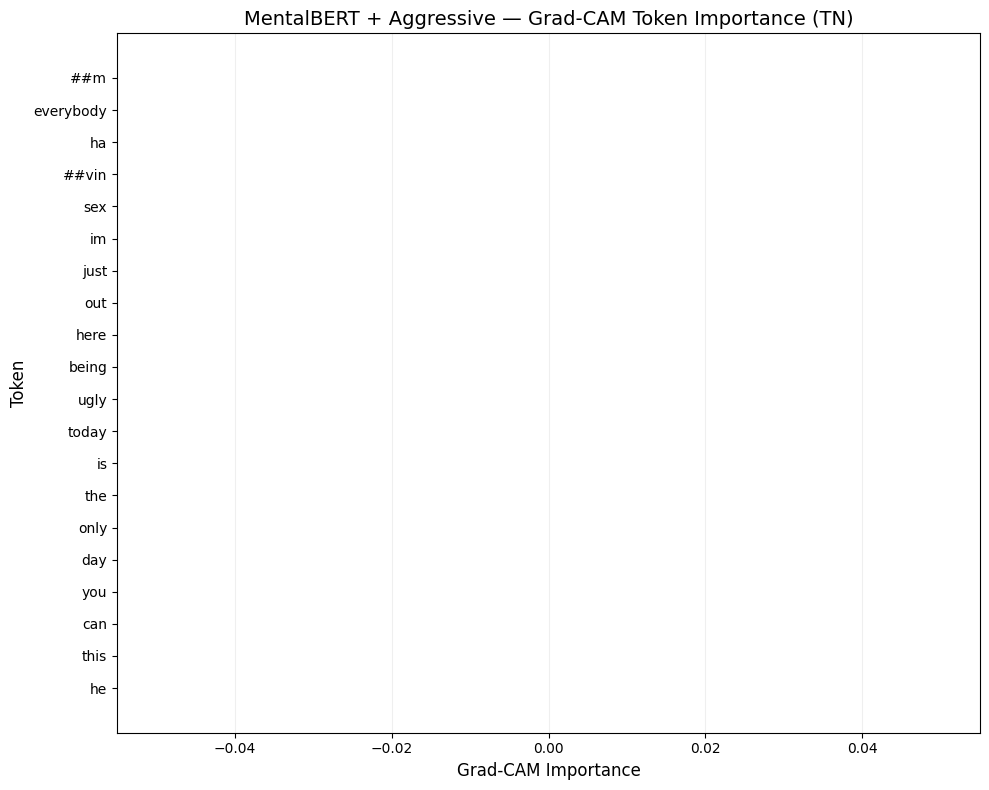

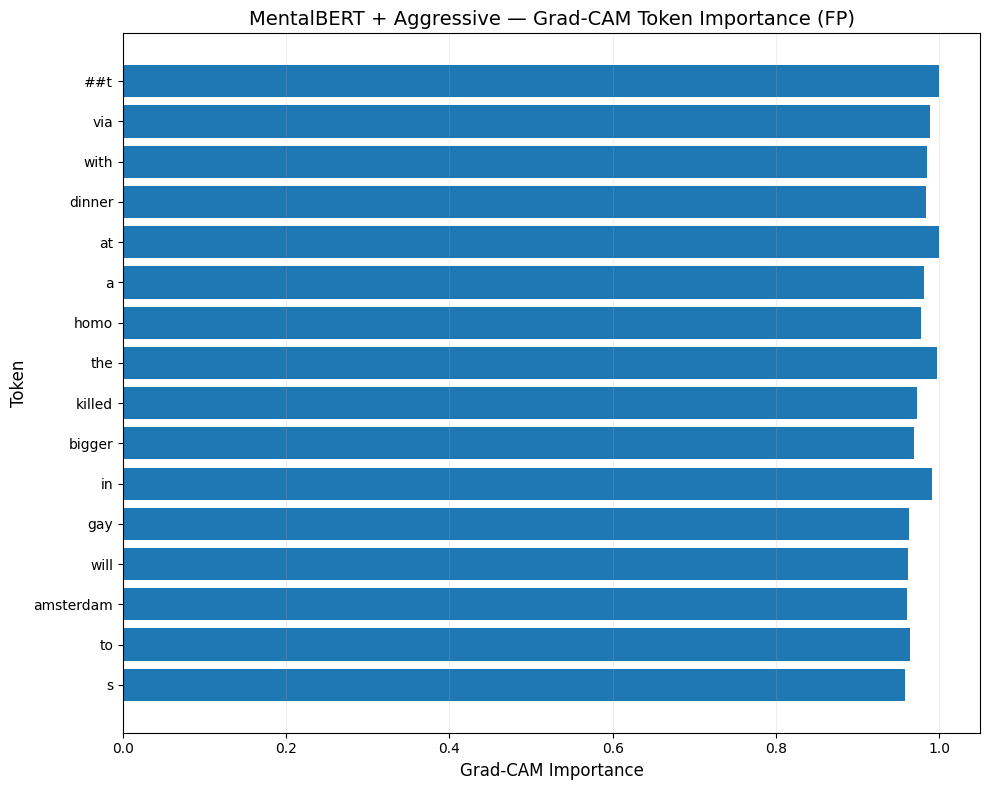

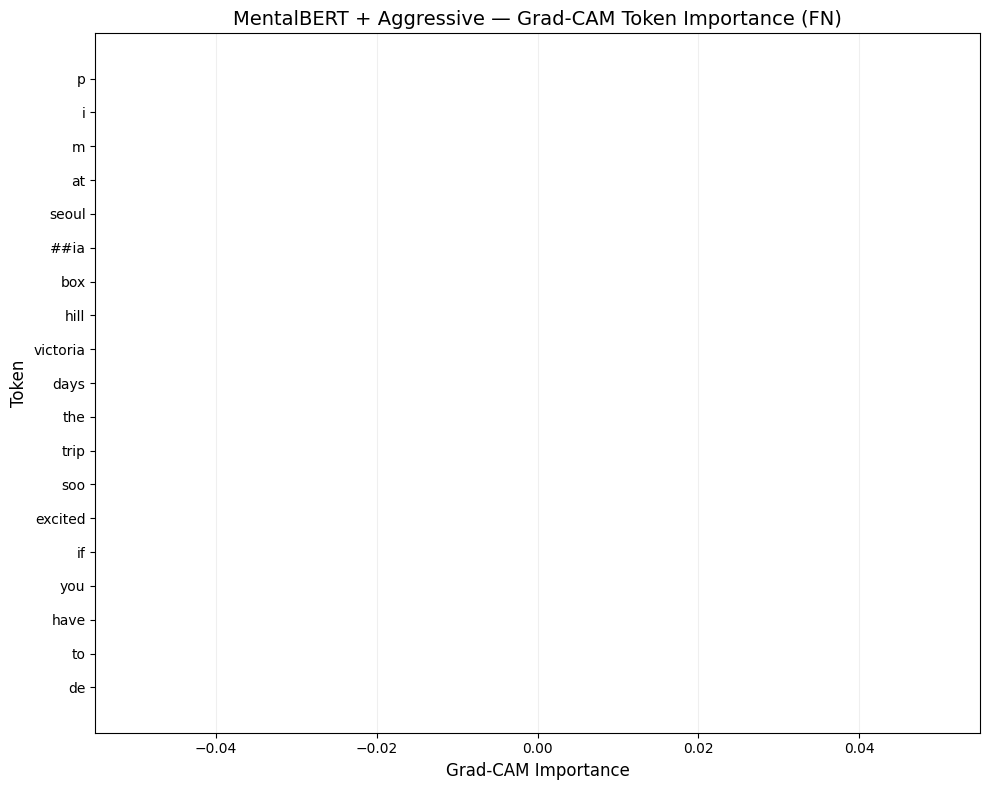


GRAD-CAM ANALYSIS COMPLETE
✓ Same TP/TN/FP/FN selection logic used
✓ Final Transformer hidden states used
✓ Positive-class gradients computed
✓ MentalBERT weights remained frozen
✓ No additional model training
✓ Token importance calculated
✓ Top-20 token plots saved and displayed
✓ Token importance CSV saved
✓ Configuration saved

Grad-CAM output directory: /kaggle/working/mentalbert_aggressive_results/explainability/gradcam


In [25]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM
# MENTALBERT + AGGRESSIVE
# TOKEN-LEVEL LOCAL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display, HTML

print("=" * 70)
print("GRAD-CAM ANALYSIS")
print("MENTALBERT + AGGRESSIVE")
print("=" * 70)

# ============================================================
# FIXED GRAD-CAM SETTINGS
# ============================================================

GRADCAM_SEED = 42
GRADCAM_TOP_TOKENS = 20

np.random.seed(
    GRADCAM_SEED
)

torch.manual_seed(
    GRADCAM_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_mental_aggressive.eval()

# Keep all model parameters frozen
for parameter in (
    model_mental_aggressive.parameters()
):

    parameter.requires_grad = False

print()
print("✓ MentalBERT model loaded")
print("✓ Evaluation mode enabled")
print("✓ All model parameters remain frozen")

# ============================================================
# BUILD TEST PREDICTIONS
# DIRECTLY FROM NOTEBOOK TEST LOADER
# ============================================================

test_labels = []
test_predictions = []
test_probabilities = []

with torch.no_grad():

    for batch in test_loader_mental_aggressive:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_mental_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        test_labels.extend(
            labels
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

        test_probabilities.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )

test_labels = np.array(
    test_labels
)

test_predictions = np.array(
    test_predictions
)

test_probabilities = np.array(
    test_probabilities
)

# ============================================================
# SELECT TP / TN / FP / FN
# SAME FIRST-MATCHING TEST ORDER
# ============================================================

selected_cases = {}

tp_candidates = np.where(
    (test_labels == 1)
    &
    (test_predictions == 1)
)[0]

tn_candidates = np.where(
    (test_labels == 0)
    &
    (test_predictions == 0)
)[0]

fp_candidates = np.where(
    (test_labels == 0)
    &
    (test_predictions == 1)
)[0]

fn_candidates = np.where(
    (test_labels == 1)
    &
    (test_predictions == 0)
)[0]

if len(tp_candidates) > 0:
    selected_cases["TP"] = int(
        tp_candidates[0]
    )

if len(tn_candidates) > 0:
    selected_cases["TN"] = int(
        tn_candidates[0]
    )

if len(fp_candidates) > 0:
    selected_cases["FP"] = int(
        fp_candidates[0]
    )

if len(fn_candidates) > 0:
    selected_cases["FN"] = int(
        fn_candidates[0]
    )

print()
print("=" * 70)
print("FIXED REPRESENTATIVE TEST CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"test index = {test_index} | "
        f"true = {test_labels[test_index]} | "
        f"pred = {test_predictions[test_index]} | "
        f"probability = "
        f"{test_probabilities[test_index]:.4f}"
    )

# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def compute_mentalbert_gradcam(
    test_index
):

    sample = test_dataset_mental_aggressive[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    # --------------------------------------------------------
    # MentalBERT forward pass
    # --------------------------------------------------------
    # Backbone parameters are frozen, but gradients are enabled
    # with respect to the hidden-state activation.
    # --------------------------------------------------------

    with torch.enable_grad():

        encoder_output = (
            model_mental_aggressive.mentalbert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        )

        hidden_states = (
            encoder_output.last_hidden_state
        )

        # Required because backbone is frozen
        hidden_states = (
            hidden_states.detach()
        )

        hidden_states.requires_grad_(True)

        hidden_states.retain_grad()

        # ----------------------------------------------------
        # EXACT ATTENTION POOLING FROM MODEL
        # ----------------------------------------------------

        projected = torch.tanh(
            model_mental_aggressive.attention_projection(
                hidden_states
            )
        )

        scores = (
            model_mental_aggressive.attention_score(
                projected
            )
            .squeeze(-1)
        )

        scores = scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention_weights = torch.softmax(
            scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # EXACT METADATA BRANCH FROM MODEL
        # ----------------------------------------------------

        metadata_representation = (
            model_mental_aggressive.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            model_mental_aggressive.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSION + CLASSIFIER
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        logits = (
            model_mental_aggressive.classifier(
                fused
            )
        )

        # Positive/depression class
        target_score = logits[
            0,
            1
        ]

        # ----------------------------------------------------
        # BACKWARD
        # ----------------------------------------------------

        model_mental_aggressive.zero_grad(
            set_to_none=True
        )

        target_score.backward()

        gradients = (
            hidden_states.grad
            .detach()
            .clone()
        )

        activations = (
            hidden_states.detach()
            .clone()
        )

    # ========================================================
    # GRAD-CAM WEIGHTS
    # ========================================================

    # Global average pooling over token positions
    channel_weights = gradients.mean(
        dim=1
    )

    # Weighted combination of hidden-state channels
    cam = torch.sum(
        activations *
        channel_weights.unsqueeze(1),
        dim=-1
    )

    # Standard Grad-CAM ReLU
    cam = torch.relu(
        cam
    )

    cam = (
        cam
        .squeeze(0)
        .cpu()
        .numpy()
    )

    attention_weights_np = (
        attention_weights
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
    )

    input_ids_np = (
        input_ids
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
    )

    # --------------------------------------------------------
    # Normalize Grad-CAM
    # --------------------------------------------------------

    valid_mask = (
        attention_mask
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
        .astype(bool)
    )

    valid_cam = cam[
        valid_mask
    ]

    if (
        valid_cam.max()
        -
        valid_cam.min()
    ) > 1e-12:

        cam_normalized = (
            cam
            -
            valid_cam.min()
        ) / (
            valid_cam.max()
            -
            valid_cam.min()
        )

    else:

        cam_normalized = (
            np.zeros_like(cam)
        )

    # Padding tokens must never receive attribution
    cam_normalized[
        ~valid_mask
    ] = 0.0

    return {
        "cam":
            cam_normalized,

        "attention_weights":
            attention_weights_np,

        "input_ids":
            input_ids_np,

        "attention_mask":
            valid_mask,

        "positive_logit":
            float(
                target_score
                .detach()
                .cpu()
                .item()
            ),

        "logits":
            logits
            .detach()
            .cpu()
            .numpy()
            .squeeze(0)
    }


# ============================================================
# TOKEN PROCESSING
# ============================================================

def get_token_information(
    result
):

    token_ids = (
        result["input_ids"]
    )

    cam = (
        result["cam"]
    )

    attention_mask = (
        result["attention_mask"]
    )

    tokens = (
        mental_aggressive_tokenizer
        .convert_ids_to_tokens(
            token_ids.tolist()
        )
    )

    rows = []

    for position, (
        token,
        importance,
        valid
    ) in enumerate(
        zip(
            tokens,
            cam,
            attention_mask
        )
    ):

        if not valid:
            continue

        # Ignore special tokens
        if (
            token
            in mental_aggressive_tokenizer.all_special_tokens
        ):
            continue

        rows.append({

            "position":
                position,

            "token":
                token,

            "importance":
                float(
                    importance
                )

        })

    token_df = pd.DataFrame(
        rows
    )

    token_df = (
        token_df
        .sort_values(
            "importance",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )

    token_df["rank"] = (
        np.arange(
            len(token_df)
        ) + 1
    )

    return token_df


# ============================================================
# RUN GRAD-CAM FOR TP/TN/FP/FN
# ============================================================

gradcam_results = {}

print()
print("=" * 70)
print("GENERATING GRAD-CAM EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    result = compute_mentalbert_gradcam(
        test_index
    )

    token_df = get_token_information(
        result
    )

    gradcam_results[
        case_name
    ] = {

        "test_index":
            test_index,

        "result":
            result,

        "token_df":
            token_df
    }

    print(
        f"✓ {case_name} Grad-CAM complete"
    )

# ============================================================
# SAVE TOKEN IMPORTANCE
# ============================================================

all_gradcam_rows = []

for case_name, data in gradcam_results.items():

    token_df = data[
        "token_df"
    ]

    for _, row in token_df.iterrows():

        all_gradcam_rows.append({

            "case":
                case_name,

            "test_index":
                data["test_index"],

            "true_label":
                int(
                    test_labels[
                        data["test_index"]
                    ]
                ),

            "predicted_label":
                int(
                    test_predictions[
                        data["test_index"]
                    ]
                ),

            "positive_probability":
                float(
                    test_probabilities[
                        data["test_index"]
                    ]
                ),

            "position":
                int(
                    row["position"]
                ),

            "token":
                row["token"],

            "gradcam_importance":
                float(
                    row["importance"]
                ),

            "rank":
                int(
                    row["rank"]
                )

        })

gradcam_results_df = pd.DataFrame(
    all_gradcam_rows
)

gradcam_csv_path = os.path.join(
    GRADCAM_DIR,
    "mentalbert_aggressive_gradcam_token_importance.csv"
)

gradcam_results_df.to_csv(
    gradcam_csv_path,
    index=False
)

# ============================================================
# PAPER-READY TOP TOKEN PLOTS
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM TOKEN IMPORTANCE")
print("=" * 70)

for case_name, data in gradcam_results.items():

    token_df = (
        data["token_df"]
        .head(
            GRADCAM_TOP_TOKENS
        )
        .copy()
    )

    # Reverse order so most important is at top
    token_df = token_df.iloc[::-1]

    plt.figure(
        figsize=(10, 8)
    )

    plt.barh(
        token_df["token"],
        token_df["importance"]
    )

    plt.xlabel(
        "Grad-CAM Importance",
        fontsize=12
    )

    plt.ylabel(
        "Token",
        fontsize=12
    )

    plt.title(
        f"MentalBERT + Aggressive — "
        f"Grad-CAM Token Importance ({case_name})",
        fontsize=14
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()

    plot_path = os.path.join(
        GRADCAM_DIR,
        f"mentalbert_aggressive_gradcam_{case_name}.png"
    )

    # SAVE
    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    # DISPLAY
    plt.show()

    plt.close()

# ============================================================
# SAVE TOP TOKEN TABLE
# ============================================================

top_token_rows = []

for case_name, data in gradcam_results.items():

    top_tokens = (
        data["token_df"]
        .head(
            GRADCAM_TOP_TOKENS
        )
    )

    for _, row in top_tokens.iterrows():

        top_token_rows.append({

            "case":
                case_name,

            "rank":
                int(
                    row["rank"]
                ),

            "token":
                row["token"],

            "gradcam_importance":
                float(
                    row["importance"]
                )

        })

top_token_df = pd.DataFrame(
    top_token_rows
)

top_token_df.to_csv(
    os.path.join(
        GRADCAM_DIR,
        "mentalbert_aggressive_gradcam_top_tokens.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Aggressive",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class logit",

    "layer":
        "Final Transformer hidden states",

    "hidden_dimension":
        768,

    "method":
        "Transformer Grad-CAM",

    "cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "top_tokens_displayed":
        GRADCAM_TOP_TOKENS,

    "random_seed":
        GRADCAM_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"

}

with open(
    os.path.join(
        GRADCAM_DIR,
        "mentalbert_aggressive_gradcam_config.json"
    ),
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Same TP/TN/FP/FN selection logic used"
)

print(
    "✓ Final Transformer hidden states used"
)

print(
    "✓ Positive-class gradients computed"
)

print(
    "✓ MentalBERT weights remained frozen"
)

print(
    "✓ No additional model training"
)

print(
    "✓ Token importance calculated"
)

print(
    "✓ Top-20 token plots saved and displayed"
)

print(
    "✓ Token importance CSV saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "Grad-CAM output directory:",
    GRADCAM_DIR
)

LIME ANALYSIS
MENTALBERT + AGGRESSIVE

✓ MentalBERT model loaded
✓ Evaluation mode enabled

FIXED REPRESENTATIVE TEST CASES
TP: test index = 1 | true = 1 | pred = 1 | probability = 0.9987
TN: test index = 2 | true = 0 | pred = 0 | probability = 0.0065
FP: test index = 0 | true = 0 | pred = 1 | probability = 0.9967
FN: test index = 68 | true = 1 | pred = 0 | probability = 0.0074

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
✓ TP explanation complete

Processing TN (test index 2)...
✓ TN explanation complete

Processing FP (test index 0)...
✓ FP explanation complete

Processing FN (test index 68)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


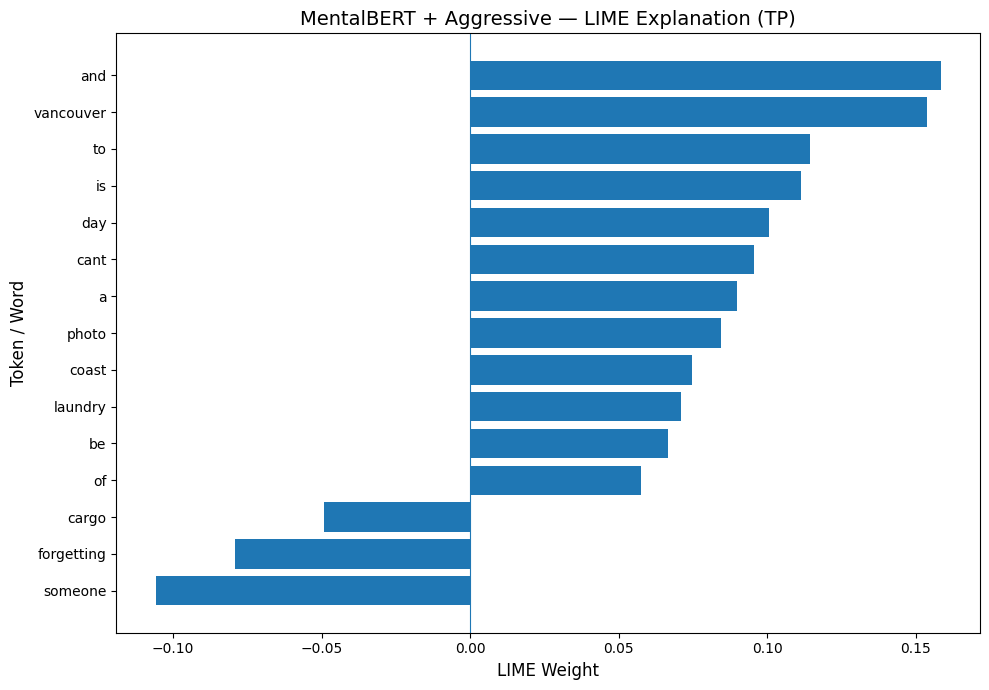

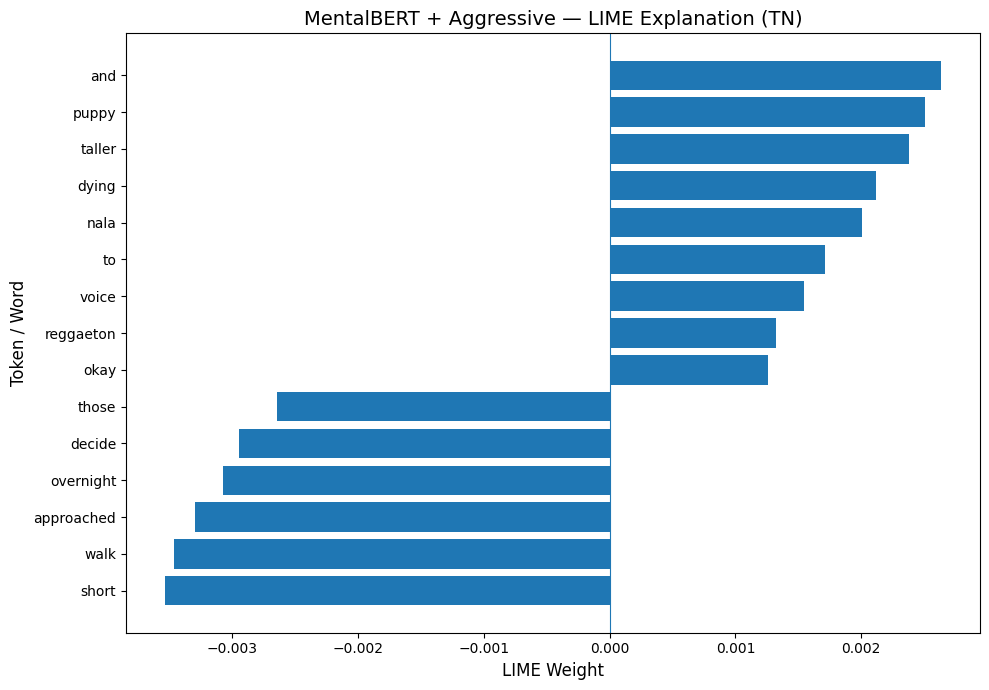

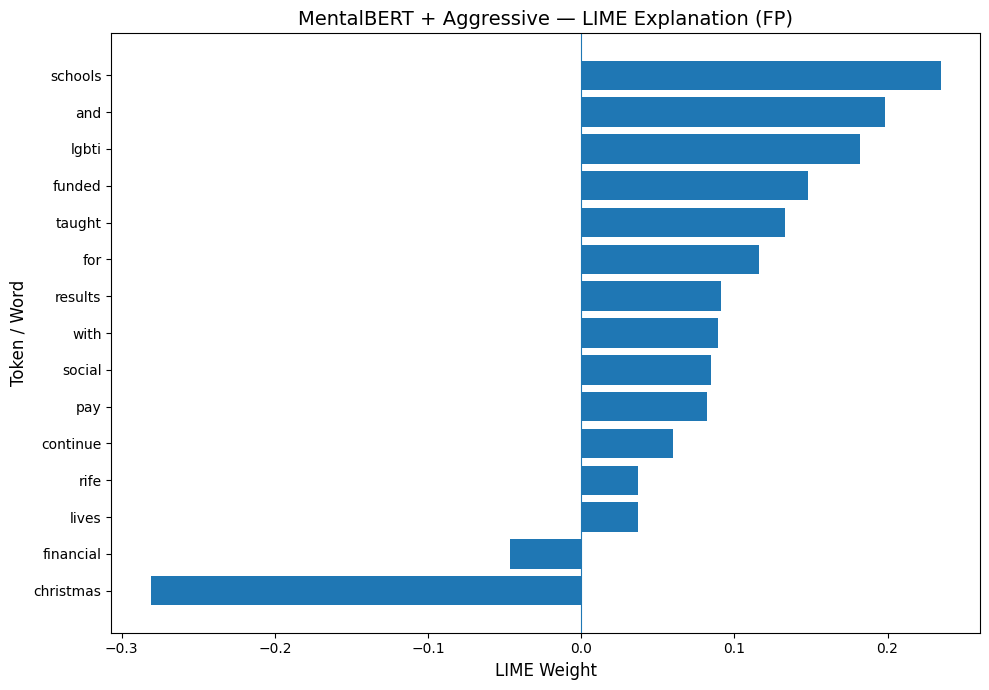

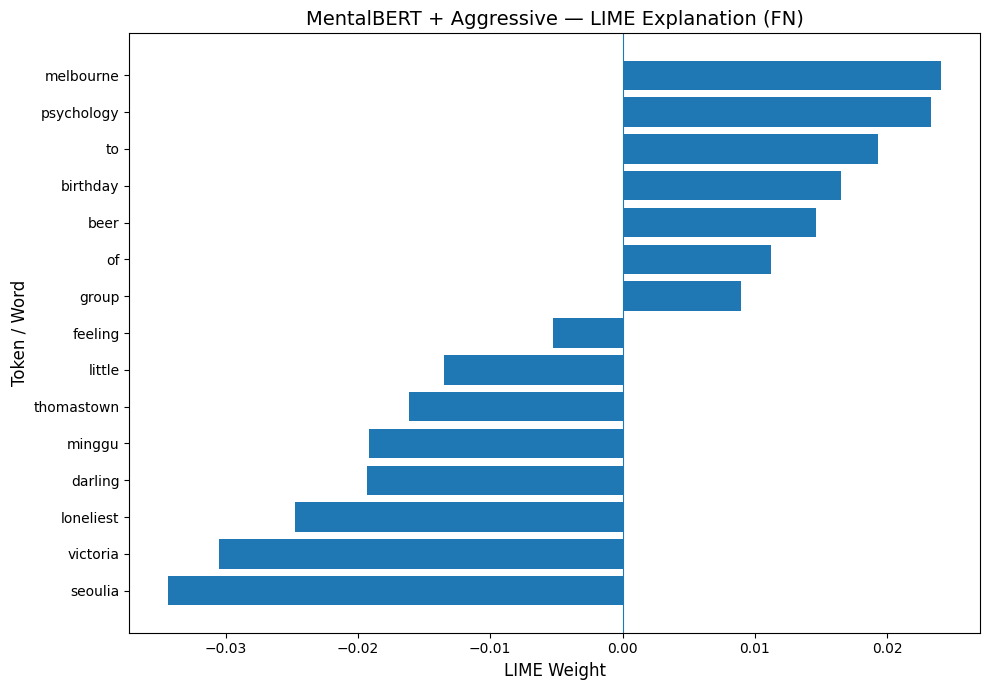


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained MentalBERT model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/mentalbert_aggressive_results/explainability/lime


In [26]:
# ============================================================
# EXPLAINABILITY — LIME
# MENTALBERT + AGGRESSIVE
# TOKEN / WORD-LEVEL LOCAL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML

print("=" * 70)
print("LIME ANALYSIS")
print("MENTALBERT + AGGRESSIVE")
print("=" * 70)

# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_SAMPLES = 1000
LIME_NUM_FEATURES = 15
LIME_BATCH_SIZE = 8

np.random.seed(
    LIME_SEED
)

torch.manual_seed(
    LIME_SEED
)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    MENTAL_AGG_RESULT_DIR,
    "explainability"
)

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_mental_aggressive.eval()

print()
print("✓ MentalBERT model loaded")
print("✓ Evaluation mode enabled")

# ============================================================
# BUILD TEST PREDICTIONS
# DIRECTLY FROM TEST LOADER
# ============================================================

labels_np = []
preds_np = []
probs_np = []

with torch.no_grad():

    for batch in test_loader_mental_aggressive:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_mental_aggressive(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        labels_np.extend(
            labels
            .cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )

labels_np = np.array(
    labels_np
)

preds_np = np.array(
    preds_np
)

probs_np = np.array(
    probs_np
)

# ============================================================
# SELECT TP / TN / FP / FN
# FIRST MATCHING TEST EXAMPLE
# ============================================================

selected_cases = {}

tp_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 1)
)[0]

tn_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 0)
)[0]

fp_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 1)
)[0]

fn_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 0)
)[0]

if len(tp_candidates) > 0:

    selected_cases["TP"] = int(
        tp_candidates[0]
    )

if len(tn_candidates) > 0:

    selected_cases["TN"] = int(
        tn_candidates[0]
    )

if len(fp_candidates) > 0:

    selected_cases["FP"] = int(
        fp_candidates[0]
    )

if len(fn_candidates) > 0:

    selected_cases["FN"] = int(
        fn_candidates[0]
    )

print()
print("=" * 70)
print("FIXED REPRESENTATIVE TEST CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"test index = {test_index} | "
        f"true = {labels_np[test_index]} | "
        f"pred = {preds_np[test_index]} | "
        f"probability = "
        f"{probs_np[test_index]:.4f}"
    )

# ============================================================
# GET TEST TEXT
# ============================================================

def get_test_text(
    test_index
):

    return str(
        test_mental_aggressive_df.iloc[
            int(test_index)
        ]["model_text"]
    )

# ============================================================
# MAKE LIME PREDICTOR
# METADATA REMAINS FIXED FOR EACH USER
# TEXT IS PERTURBED BY LIME
# ============================================================

def make_lime_predictor(
    test_index
):

    sample = test_dataset_mental_aggressive[
        int(test_index)
    ]

    fixed_metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
        .float()
    )

    def predictor(
        texts
    ):

        probability_batches = []

        # ----------------------------------------------------
        # Process perturbations in small batches
        # to avoid GPU memory overflow.
        # ----------------------------------------------------

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            batch_texts = texts[
                start:
                start + LIME_BATCH_SIZE
            ]

            encoded = mental_aggressive_tokenizer(
                batch_texts,
                padding="max_length",
                truncation=True,
                max_length=MAX_LENGTH,
                return_attention_mask=True,
                return_tensors="pt"
            )

            lime_input_ids = (
                encoded["input_ids"]
                .to(device)
            )

            lime_attention_mask = (
                encoded["attention_mask"]
                .to(device)
            )

            batch_metadata = (
                fixed_metadata.expand(
                    len(batch_texts),
                    -1
                )
            )

            with torch.no_grad():

                output = model_mental_aggressive(
                    input_ids=lime_input_ids,
                    attention_mask=lime_attention_mask,
                    metadata=batch_metadata
                )

                probabilities = torch.softmax(
                    output["logits"],
                    dim=1
                )

            probability_batches.append(
                probabilities
                .cpu()
                .numpy()
            )

            del (
                lime_input_ids,
                lime_attention_mask,
                batch_metadata,
                output,
                probabilities
            )

            if torch.cuda.is_available():

                torch.cuda.empty_cache()

        return np.vstack(
            probability_batches
        )

    return predictor

# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)

# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}

print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    text = get_test_text(
        test_index
    )

    predictor = make_lime_predictor(
        test_index
    )

    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )

    all_explanations[
        case_name
    ] = explanation

    print(
        f"✓ {case_name} explanation complete"
    )

# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []

for case_name, explanation in all_explanations.items():

    explanation_list = (
        explanation.as_list(
            label=1
        )
    )

    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(
                    weight
                )

        })

lime_results_df = pd.DataFrame(
    all_lime_rows
)

lime_csv_path = os.path.join(
    LIME_DIR,
    "mentalbert_aggressive_lime_results.csv"
)

lime_results_df.to_csv(
    lime_csv_path,
    index=False
)

# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)

for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )

    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )

    html_path = os.path.join(
        LIME_DIR,
        f"mentalbert_aggressive_lime_{case_name}.html"
    )

    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )

# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = (
        explanation.as_list(
            label=1
        )
    )

    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )

    plot_df = plot_df.sort_values(
        "weight"
    )

    plt.figure(
        figsize=(10, 7)
    )

    plt.barh(
        plot_df["word"],
        plot_df["weight"]
    )

    plt.axvline(
        0,
        linewidth=0.8
    )

    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )

    plt.ylabel(
        "Token / Word",
        fontsize=12
    )

    plt.title(
        f"MentalBERT + Aggressive — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )

    plt.tight_layout()

    plot_path = os.path.join(
        LIME_DIR,
        f"mentalbert_aggressive_lime_{case_name}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []

for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )

    })

case_info_df = pd.DataFrame(
    case_info_rows
)

case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "mentalbert_aggressive_lime_case_information.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Aggressive",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training"
}

with open(
    os.path.join(
        LIME_DIR,
        "mentalbert_aggressive_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained MentalBERT model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    f"✓ {LIME_NUM_SAMPLES} LIME perturbations per case"
)

print(
    f"✓ Top {LIME_NUM_FEATURES} features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()

print(
    "LIME output directory:",
    LIME_DIR
)